# Can a vision model read the tests ordered on a lab requisition?

## A paper form between the doctor and the lab

When a family doctor in Ontario wants blood work for a patient, the order usually travels on paper. The doctor fills in the province's Laboratory Requisition, a one-page form with the number 4422-84 printed in its corner. The patient carries it to a collection centre, or the clinic faxes or scans it ahead. Before anyone draws blood, someone at the lab reads the page and types the order into the lab's computer system: who the patient is, which clinician gets the results, and which tests to run.

The top of the form holds the details: the patient's name, health card number, date of birth, sex, address and phone, and the clinician's name, clinic, address, registration numbers and urgent-results phone. The lower half is a grid of several dozen printed test names, each with a small box in a narrow column to its left. A mark in the box orders that test. A test that is not printed on the form goes on one of the "Other Tests" lines at the right, one test per line, typed or written by hand.

Each kind of reading mistake has a cost. A test that is missed is never run, so the patient may need a second blood draw and the doctor waits for a result that never arrives. A test that is added costs money and produces a result nobody asked for. A wrong date of birth or health number can stop the lab from matching the patient's record, or attach the result to the wrong person.

### An illustrative example

This example is made up, but it follows the real form's layout.

A doctor wants to check a patient's potassium. Potassium is printed on the form, so she puts an X in its box. In the ordinary case the clerk sees one mark, reads the name beside it and enters Potassium.

Now add one complication. The doctor also wants ferritin, the usual blood test for iron stores, and ferritin is not printed on the form. So she writes "Ferritin" on the first Other Tests line. The page now has one mark and one written line, and the right answer is two tests: Potassium and Ferritin. A careful clerk reads the boxes and then the Other Tests lines. A reader that looks only for marks enters Potassium alone, and the ferritin is never measured. A reader that lists every test name printed on the page enters dozens of tests the doctor never ordered. Both kinds of mistake appear in the results below.

The page may also arrive as a phone photo: taken at an angle, with a shadow across it, or held sideways. The marks are the same, but the boxes are smaller, slanted and harder to line up with their names.

### Why test this, and how

Vision-language models are language models that also take images: given a picture of a page and an instruction, they write text about it. One could read a requisition and return the order as structured data for a clerk to confirm. Before a lab relies on one, it needs three separate numbers: how often the model misses an ordered test, how often it adds a test nobody ordered, and how often it copies a patient or clinician detail wrong. A single "accuracy" figure would hide which of these happens.

Measuring them needs requisitions whose correct contents are known exactly. Real ones contain health information and cannot be published, and their correct contents would have to be typed in by hand, with errors of their own. So this study uses synthetic requisitions. A program fills in the official form with made-up patients and orders, records exactly what it wrote and where, and then makes the page look scanned or photographed. Some values are typed and some are drawn in a script font that imitates handwriting. Every page is stamped "SYNTHETIC - NOT FOR CLINICAL USE" and every identifier is deliberately invalid. Because the filled pages were generated for this test, no model can have seen them, or their answers, during training.

Two kinds of model are compared. Hosted models run on their maker's servers, so the page leaves the lab; three are tested, Claude Opus 5.5 from Anthropic, GPT-6.1 from OpenAI and Muse Wonder from Meta. Open-weight models have their trained files published, so a lab could run one on its own hardware and keep patient pages in-house; four are tested, Qwen3.8 Flash, Gemma 4 31B, Nemotron 3.5 Super VL and Muse Spark Open. Here they were reached through OpenRouter, a service that hosts many open-weight models. The comparison shows how much reading accuracy a lab gives up, on these forms, by choosing a model it could run itself.

## The question

Given a scanned or photographed Ontario lab requisition, can a vision-language model list exactly the tests that were ordered, including the ones written on the Other Tests lines, and copy the patient and clinician details correctly? How do three hosted models and four open-weight models compare on 24 synthetic requisitions whose contents are known exactly?

A lab deciding whether to let a model pre-fill orders needs to know which of these parts it can trust, and on which kind of page.

## Study summary

Each of seven models read each of 24 requisitions once, with the same instructions: 10 flatbed scans of the official form, 8 phone photos of it and 6 scans of a simpler Ontario-style layout. The pages order 102 tests in total, 75 by a mark in a box and 27 on Other Tests lines, and each page has 20 scored details (480 per model). A fixed program compared every reply with the generator's record; no model judged another.

The main measure for tests is F1. It combines precision, the share of listed tests that were really ordered, with recall, the share of ordered tests that were listed. An F1 of 1.00 means no test missed and none added; the scoring section below works through an example.

- Claude Opus 5.5 listed exactly the ordered tests on all 24 pages: 102 of 102 found, none added (F1 1.00). GPT-6.1 missed 1 test and Muse Wonder added 3, all on phone photos (F1 0.995 and 0.986). The three hosted models sit at the ceiling of this test and are separated by 4 tests out of 102, so it cannot rank them on tests.
- The best open-weight model, Muse Spark Open, reached F1 0.94 with the exact list on 20 of 24 pages. Its one empty reply is the only one of the 168 that could not be read; on its 23 readable replies F1 is 0.97. Nemotron 3.5 Super VL (0.81 overall) scored 0.99 on scans of the official form and Qwen3.8 Flash (0.80) scored 0.91, but each returned one phone-photo reply that listed most of the tests printed on the form. Those two replies hold 28 of Nemotron's 38 added tests and 22 of Qwen's 28. Gemma 4 31B (0.52) added more tests than it found, 91 against 68.
- Tests written on the Other Tests lines were the open models' weak point: together they found 66 of 108, against 275 of 300 tests marked in boxes. The hosted models found 80 of 81.
- For patient and clinician details, Claude copied 464 of 480 exactly (96.7%), GPT-6.1 88.3% and Muse Wonder 91.5%. Almost all of the gap is on phone photos: on scans of the official form the three copied 97.5% to 99.5% of details, on photos 90.6%, 67.5% and 77.5%. The date of birth was the hardest detail (right in 114 of 168 replies); years in a handwriting-style font inside the official form's boxed date area were read correctly 7 times out of 42.

In the original situation: on forms like these, Claude Opus 5.5 could pre-fill the test list for a clerk to confirm, and the other two hosted models nearly could. None of the seven should fill in patient details from a phone photo unchecked. With an open-weight model, a person needs to check the Other Tests lines, every phone photo, and any reply that lists far more tests than a requisition carries.

The main caveat is that these are 24 synthetic pages with simulated marks, a script font standing in for handwriting and simulated camera effects, each read once by each model. Real faxes, pen ticks, stamps and handwriting will add failures not tested here, and Claude's 0 misses in 102 tests still allows a true miss rate of up to 3.6%.

## Contents
1. [Setup and configuration](#1.-Setup-and-configuration)
2. [Data: the synthetic requisitions and their ground truth](#2.-Data:-the-synthetic-requisitions-and-their-ground-truth)
3. [Prompt, models and extraction](#3.-Prompt,-models-and-extraction)
4. [Scoring rules and a worked example](#4.-Scoring-rules-and-a-worked-example)
5. [Results: ordered tests](#5.-Results:-ordered-tests)
6. [Results: patient, clinician and order details](#6.-Results:-patient,-clinician-and-order-details)
7. [Error analysis](#7.-Error-analysis)
8. [What the evidence supports](#8.-What-the-evidence-supports)
9. [Cost, latency, limitations and reproduction](#9.-Cost,-latency,-limitations-and-reproduction)
10. [Future work and further reading](#10.-Future-work-and-further-reading)

## Workflow
The whole experiment from data to results, with the counts from this run. Every model reply is cached in `data/`, so running the notebook again replays the replies without calling any model.

```mermaid
flowchart TD
    gen["Synthetic requisition generator<br/>seeds 4422, 8424, 2284"]
    docs["24 requisition images<br/>10 official-form scans, 8 phone photos,<br/>6 Ontario-style scans"]
    gt["Ground truth per image<br/>20 scored details (480 in all), 102 ordered tests<br/>(75 in boxes, 27 written in), a box around every mark"]
    prompt["One prompt for every model<br/>output format, 31 standard test names, the marking rule"]
    cli["3 hosted models via their CLIs, effort medium<br/>Claude Opus 5.5, GPT-6.1, Muse Wonder<br/>72 calls"]
    open["4 open-weight models via OpenRouter, temperature 0<br/>Qwen3.8 Flash, Gemma 4 31B, Nemotron 3.5 Super VL, Muse Spark Open<br/>96 calls; 8 retried with 20,000 output tokens"]
    parse["Find the JSON object in each reply<br/>167 of 168 readable; 1 empty (Muse Spark Open, form-scan-05)"]
    score["Fixed scoring program<br/>3,360 detail checks, 876 test checks"]
    res["Test F1: Claude Opus 5.5 1.00, GPT-6.1 0.995, Muse Wonder 0.986,<br/>best open-weight model 0.94 (Muse Spark Open)"]
    gen --> docs
    gen --> gt
    docs --> cli
    docs --> open
    prompt --> cli
    prompt --> open
    cli --> parse
    open --> parse
    parse --> score
    gt --> score
    score --> res
```

One page travels through it like this: form-scan-01 and the shared prompt go to each of the seven models, each reply is searched for its JSON object, and the object's 20 details and test list are compared with form-scan-01's ground-truth file. Section 4.1 follows that page step by step.

## 1. Setup and configuration
The next cell loads the libraries, sets the folders and defines the size knobs and the plot style. The knobs decide what a run costs. `N_DOCS` is the number of pages (24, or 3 when the environment variable `NB_SMOKE=1` is set). `CLI_MODELS` lists the three hosted models with the command-line tool and reasoning effort for each, and `OPEN_MODELS` lists the four open-weight models by their OpenRouter names.

Hosted models are billed to the `claude`, `codex` and `muse` subscriptions; open-weight models are paid per call through OpenRouter (`OPENROUTER_API_KEY`). Every reply is cached in `data/cache_*.jsonl`, so running the notebook again makes no calls and costs nothing.

In [1]:
import base64, hashlib, json, mimetypes, os, re, shutil, subprocess, tempfile, threading, time, unicodedata, uuid
from concurrent.futures import ThreadPoolExecutor
import warnings
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from cycler import cycler
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from PIL import Image

ROOT = Path.cwd()
DATA, FIG = ROOT / "data", ROOT / "figures"
FIG.mkdir(exist_ok=True)

# ---- size knobs -------------------------------------------------------------------------------------
SMOKE = os.environ.get("NB_SMOKE") == "1"
N_DOCS = 3 if SMOKE else 24          # documents to evaluate (max 24)
CLI_MODELS = {                       # label -> (backend, model id, reasoning effort)
    "Claude Opus 5.5": ("claude", "claude-opus-5-5", "medium"),
    "GPT-6.1 (Codex)": ("codex", "gpt-6.1-sol", "medium"),
    "Muse Wonder": ("muse", "muse-wonder-full-1.0", "medium"),
}
OPEN_MODELS = {                      # label -> OpenRouter model id (open weights, vision input)
    "Qwen3.8 Flash": "qwen/qwen3.8-flash",
    "Gemma 4 31B": "google/gemma-4-31b-it",
    "Nemotron 3.5 Super VL": "nvidia/nemotron-3.5-super-vl",
    "Muse Spark Open": "meta/muse-spark-open",
}
WORKERS = {"claude": 4, "codex": 2, "muse": 3, "openrouter": 6}

# ---- plot style -------------------------------------------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
GOOD, BAD, WARN = "#1baf7a", "#e34948", "#eda100"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9.5, "legend.frameon": False,
    "axes.prop_cycle": cycler(color=PALETTE),
})
pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", category=FutureWarning)  # pandas groupby.apply notices

### 1.1 Helpers: cache, model calls and reply parsing
The next cell defines the helpers the rest of the notebook uses, so that every model call goes through one place.

- A disk cache keyed by a hash of the full request (model, prompt, image and settings). A reply is saved the first time and read back on every later run. A failed call is not saved, so a later run tries it again.
- Three wrappers that run the hosted models' command-line tools with their tools switched off, in an empty temporary folder. Claude receives the image inside the message; GPT-6.1 and Muse Wonder receive it as an attached file. A wrapper tries a failed call up to 4 times, waiting longer after a rate-limit message.
- A client for the open-weight models on OpenRouter, which sends the image and the prompt at temperature 0 and retries HTTP errors up to 5 times.
- A parser that finds the first complete JSON object with a `patient` key anywhere in a reply. Models often wrap their JSON in a code fence or add a sentence around it; the parser accepts both, so a reply counts as unreadable only when it contains no such object.

The printed line shows which tools were installed when the notebook last ran. The OpenRouter key was not set, so every reply came from the cache.

In [2]:
class JsonlCache:
    """Append-only on-disk cache, keyed by sha256 of the request."""

    def __init__(self, path):
        self.path, self.lock, self.data = Path(path), threading.Lock(), {}
        if self.path.exists():
            for line in self.path.read_text(encoding="utf-8").splitlines():
                row = json.loads(line)
                self.data[row["key"]] = row["value"]

    def get(self, request, fn):
        k = hashlib.sha256(json.dumps(request, sort_keys=True).encode()).hexdigest()
        if k not in self.data:
            value = fn(request)
            if isinstance(value, dict) and "error" in value:
                return value  # failures are not cached, so a re-run retries them
            with self.lock:
                self.data[k] = value
                with self.path.open("a", encoding="utf-8") as f:
                    f.write(json.dumps({"key": k, "value": value}) + "\n")
        return self.data[k]


def file_digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:16]


def b64(path):
    return base64.b64encode(Path(path).read_bytes()).decode()


CLAUDE, CODEX, MUSE = shutil.which("claude"), shutil.which("codex"), shutil.which("muse")
WORKDIR = Path(tempfile.mkdtemp(prefix="nb09_"))
cli_cache = JsonlCache(DATA / "cache_cli.jsonl")
or_cache = JsonlCache(DATA / "cache_openrouter.jsonl")


def run_claude(prompt, model, images=(), effort=None, timeout=900):
    content = [{"type": "image", "source": {"type": "base64", "media_type": mimetypes.guess_type(str(p))[0], "data": b64(p)}}
               for p in images] + [{"type": "text", "text": prompt}]
    cmd = [CLAUDE, "-p", "--model", model, "--tools", "", "--safe-mode", "--no-session-persistence",
           "--input-format", "stream-json", "--output-format", "stream-json", "--verbose"]
    if effort:
        cmd += ["--effort", effort]
    msg = {"type": "user", "message": {"role": "user", "content": content}}
    r = subprocess.run(cmd, input=json.dumps(msg) + "\n", capture_output=True, text=True, encoding="utf-8",
                       timeout=timeout, cwd=WORKDIR)
    for line in reversed(r.stdout.splitlines()):
        if line.startswith("{") and '"type":"result"' in line.replace(" ", ""):
            o = json.loads(line)
            if o.get("is_error"):
                raise RuntimeError(str(o.get("result"))[:300])
            return {"text": o["result"], "list_cost_usd": o.get("total_cost_usd")}
    raise RuntimeError(f"claude failed: {r.stderr[-400:]}")


def run_codex(prompt, model, images=(), effort="medium", timeout=900):
    cmd = [CODEX, "exec", "--skip-git-repo-check", "--ephemeral", "--ignore-user-config", "--sandbox",
           "read-only", "-m", model, "-c", f"model_reasoning_effort={effort}"]
    for p in images:
        cmd += ["-i", str(p)]
    cmd += ["--json", "-"]
    r = subprocess.run(cmd, input=prompt, capture_output=True, text=True, encoding="utf-8", timeout=timeout, cwd=WORKDIR)
    text, err = None, None
    for line in r.stdout.splitlines():
        if line.startswith("{"):
            o = json.loads(line)
            if o.get("type") == "item.completed" and o["item"].get("type") == "agent_message":
                text = o["item"]["text"]
            elif o.get("type") in ("turn.failed", "error"):
                err = str(o)[:300]
    if text is None:
        raise RuntimeError(f"codex failed: {err or r.stderr[-400:]}")
    return {"text": text}


def run_muse(prompt, model, images=(), effort="medium", timeout=900):
    pf = WORKDIR / f"prompt_{uuid.uuid4().hex}.txt"
    pf.write_text(prompt, encoding="utf-8")
    cmd = [MUSE, "exec", "--preset", "empty", "--no-session-log", "--disable-web-tools", "--model", model,
           "--reasoning-effort", effort, "--prompt-file", str(pf)]
    for p in images:
        cmd += ["--image", str(p)]
    r = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", timeout=timeout, cwd=WORKDIR)
    pf.unlink(missing_ok=True)
    if r.returncode != 0 or not r.stdout.strip():
        raise RuntimeError(f"muse failed: {r.stderr[-400:]}")
    return {"text": r.stdout.strip()}


RUNNERS = {"claude": run_claude, "codex": run_codex, "muse": run_muse}


def ask_cli(backend, model, prompt, images=(), effort="medium", tries=4):
    request = {"backend": backend, "model": model, "effort": effort, "prompt": prompt,
               "images": [file_digest(p) for p in images]}

    def call(_):
        last = None
        for _attempt in range(tries):
            t0 = time.perf_counter()
            try:
                out = RUNNERS[backend](prompt, model, images=images, effort=effort)
                out["latency_s"] = time.perf_counter() - t0
                return out
            except Exception as e:  # noqa: BLE001 - a failed call is returned, not fatal
                last = str(e)[:300]
                if "429" in last or "rate limit" in last.lower() or "usage limit" in last.lower():
                    time.sleep(30 * 2 ** _attempt)  # back off on subscription rate limits
        return {"error": last}

    return cli_cache.get(request, call)


def ask_openrouter(model, prompt, image, max_tokens=6000, tries=5):
    request = {"model": model, "prompt": prompt, "image": file_digest(image), "max_tokens": max_tokens}

    def call(_):
        key = os.environ.get("OPENROUTER_API_KEY")
        if not key:
            raise RuntimeError("Not in the cache and OPENROUTER_API_KEY is not set")
        payload = {"model": model, "temperature": 0, "max_tokens": max_tokens, "usage": {"include": True},
                   "messages": [{"role": "user", "content": [
                       {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{b64(image)}"}},
                       {"type": "text", "text": prompt}]}]}
        for attempt in range(tries):
            t0 = time.perf_counter()
            r = requests.post("https://openrouter.ai/api/v1/chat/completions", json=payload, timeout=600,
                              headers={"Authorization": f"Bearer {key}"})
            if r.status_code == 200 and r.json().get("choices"):
                o = r.json()
                return {"text": o["choices"][0]["message"].get("content") or "", "usage": o.get("usage", {}),
                        "latency_s": time.perf_counter() - t0, "provider": o.get("provider")}
            if attempt < tries - 1:
                time.sleep(2 ** attempt * 2)
        return {"error": f"HTTP {r.status_code}: {r.text[:300]}"}

    return or_cache.get(request, call)


def first_json(text, key=None):
    """First complete JSON object in a reply (optionally the first one with `key`). Tolerates code fences,
    prose around it, and replies that repeat the object."""
    dec = json.JSONDecoder()
    for m in re.finditer(r"\{", text or ""):
        try:
            obj, _ = dec.raw_decode(text, m.start())
        except json.JSONDecodeError:
            continue
        if isinstance(obj, dict) and (key is None or key in obj):
            return obj
    return None


def parse_json(text):
    return first_json(text, key="patient")  # the top-level object; a cut-off reply has none


def pmap(fn, items, workers):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(fn, items))


print("CLIs found:", {"claude": bool(CLAUDE), "codex": bool(CODEX), "muse": bool(MUSE)},
      "| OpenRouter key:", bool(os.environ.get("OPENROUTER_API_KEY")))

CLIs found: {'claude': True, 'codex': True, 'muse': True} | OpenRouter key: False


## 2. Data: the synthetic requisitions and their ground truth

### 2.1 How the documents were made
The pages come from a synthetic requisition generator. For the official layout it draws on the public printable form 4422-84, edition 2026/04; each ground-truth file records the official PDF's download address and its SHA-256 hash. It fills the form with made-up patients, clinicians and test orders, then simulates either a flatbed scan (slight rotation, blur, JPEG compression, speckle) or a phone photo (perspective, framing, lighting, shadows, glare and the way the phone was held). For every image it writes the exact value of every filled field and a bounding box for every field and every mark. The images are in `data/images/` and the ground truth in `data/ground_truth/`.

| Subset (label in the figures) | Pages | Seed | What the page looks like | Ordered tests |
|---|---:|---:|---|---|
| Official-form scans (`4422-84 scan`) | 10 | 4422 | Flatbed scan of the official form, turned by less than 1.4 degrees, blurred, compressed and speckled | 47: 29 in boxes, 18 written in |
| Phone photos (`4422-84 phone photo`) | 8 | 8424 | Photo of the official form lying on a surface: 5 upright, 2 sideways, 1 upside down; perspective, shadow, and glare on one | 32: 23 in boxes, 9 written in |
| Ontario-style scans (`Ontario-style scan`) | 6 | 2284 | Flatbed scan of a simpler layout that prints all 31 test names used here, each with its own box, and writes dates as one string | 23, all in boxes |

Counted from `data/manifest.csv` and the ground-truth files in `data/ground_truth/` (fields `document.scan` and `order.tests`). Each page orders 2 to 7 tests.

On data freshness: the filled pages were generated in code from fixed seeds (each ground-truth file has `source.deterministic: true`), so no model can have seen them. The blank official form is public and may have been. `data/` does not record when the pages were rendered, who built the generator or where it is kept, and it records no release date or training cutoff for any of the seven models.

The next cell reads the list of pages and their ground-truth files and counts the pages by subset and by how each was captured.

In [3]:
manifest = pd.read_csv(DATA / "manifest.csv").head(N_DOCS)
GT = {d: json.loads((DATA / "ground_truth" / f"{d}.json").read_text(encoding="utf-8")) for d in manifest.doc_id}
manifest["subset"] = manifest.doc_id.str.rsplit("-", n=1).str[0].map(
    {"form-scan": "4422-84 scan", "form-photo": "4422-84 phone photo", "style-scan": "Ontario-style scan"})
manifest["path"] = manifest.doc_id.map(lambda d: DATA / "images" / f"{d}.jpg")
print(manifest.groupby(["subset", "orientation"]).size().rename("documents").to_string())

subset               orientation    
4422-84 phone photo  landscape_right     2
                     portrait            5
                     upside_down         1
4422-84 scan         flatbed            10
Ontario-style scan   flatbed             6


The counts match the design: 10 official-form scans and 6 Ontario-style scans, all flatbed, and 8 phone photos, of which 5 were taken upright (`portrait`), 2 sideways (`landscape_right`) and 1 upside down. These 8 photos turn out to be the hardest pages for every model (sections 5 and 6).

The next cell shows one page from each subset as the models received it (1,700 x 2,200 pixels), with the page ID and subset in each title. Look at the lower half of each page, where the tests are.

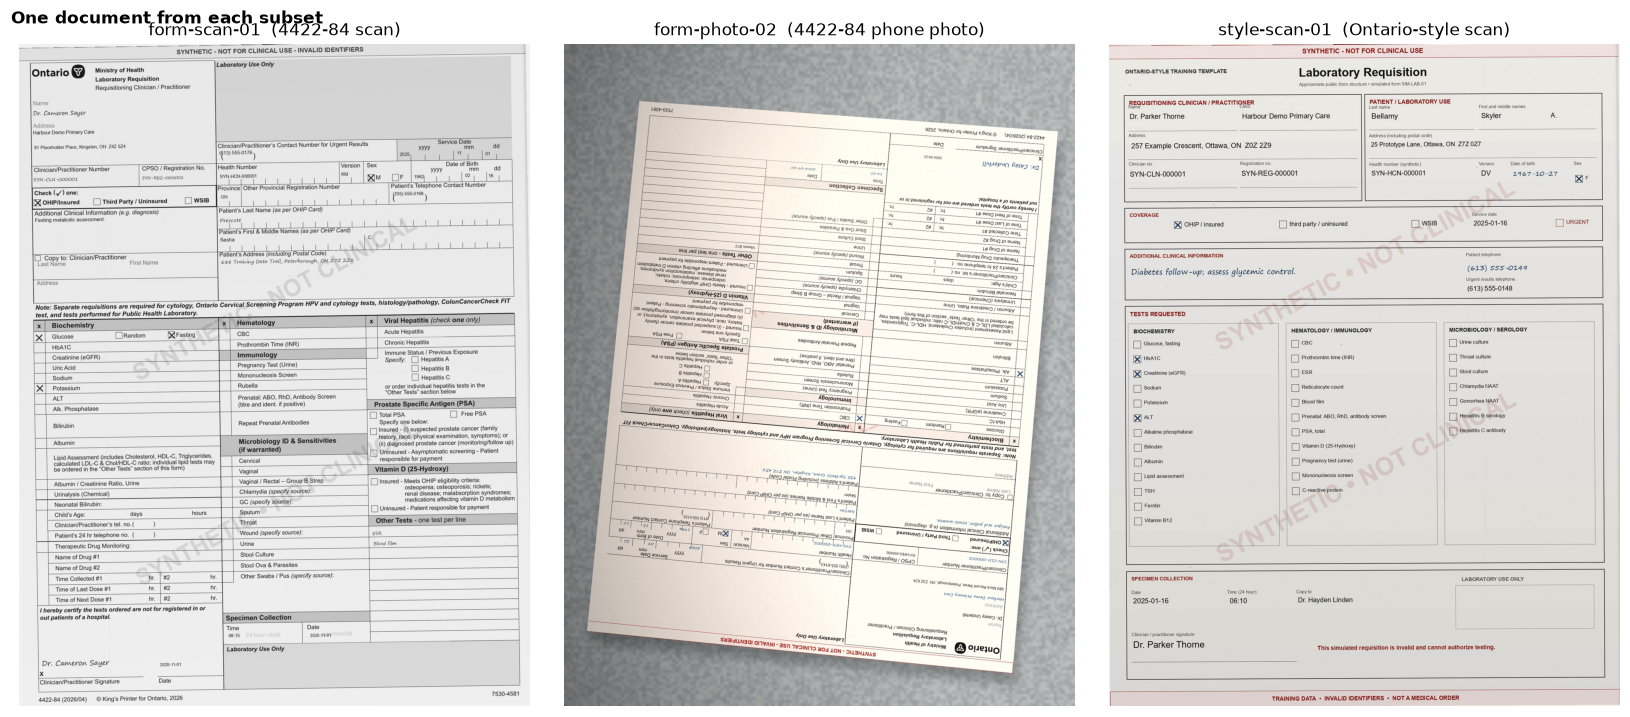

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6.6))
for ax, doc in zip(axes, ["form-scan-01", "form-photo-02", "style-scan-01"]):
    if doc in GT:
        ax.imshow(Image.open(DATA / "images" / f"{doc}.jpg"))
        ax.set_title(f"{doc}  ({manifest.set_index('doc_id').subset.get(doc)})", loc="center", fontweight="normal")
    ax.axis("off")
fig.suptitle("One document from each subset", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); fig.savefig(FIG / "subsets.png"); plt.show()

On the official form (left and middle) the tests sit in a dense grid with the box column to the left of each name, and the Other Tests lines are at the lower right, where form-scan-01 has "ESR" and "Blood film" in a script font. The photo in the middle is the same layout upside down and slanted, filling only part of the frame. The Ontario-style page on the right is the easy reference: three short labelled lists with wide spacing, and the date of birth written as one string rather than in separate boxes.

### 2.2 Close-up: what a "marked test" looks like
The next cell crops the test grid of form-scan-01 and draws the ground-truth box around each ordered test: blue for a test ordered by a mark in its box, orange for a test written on an Other Tests line. Look at the Glucose row, which has two marks, and at the right-hand column.

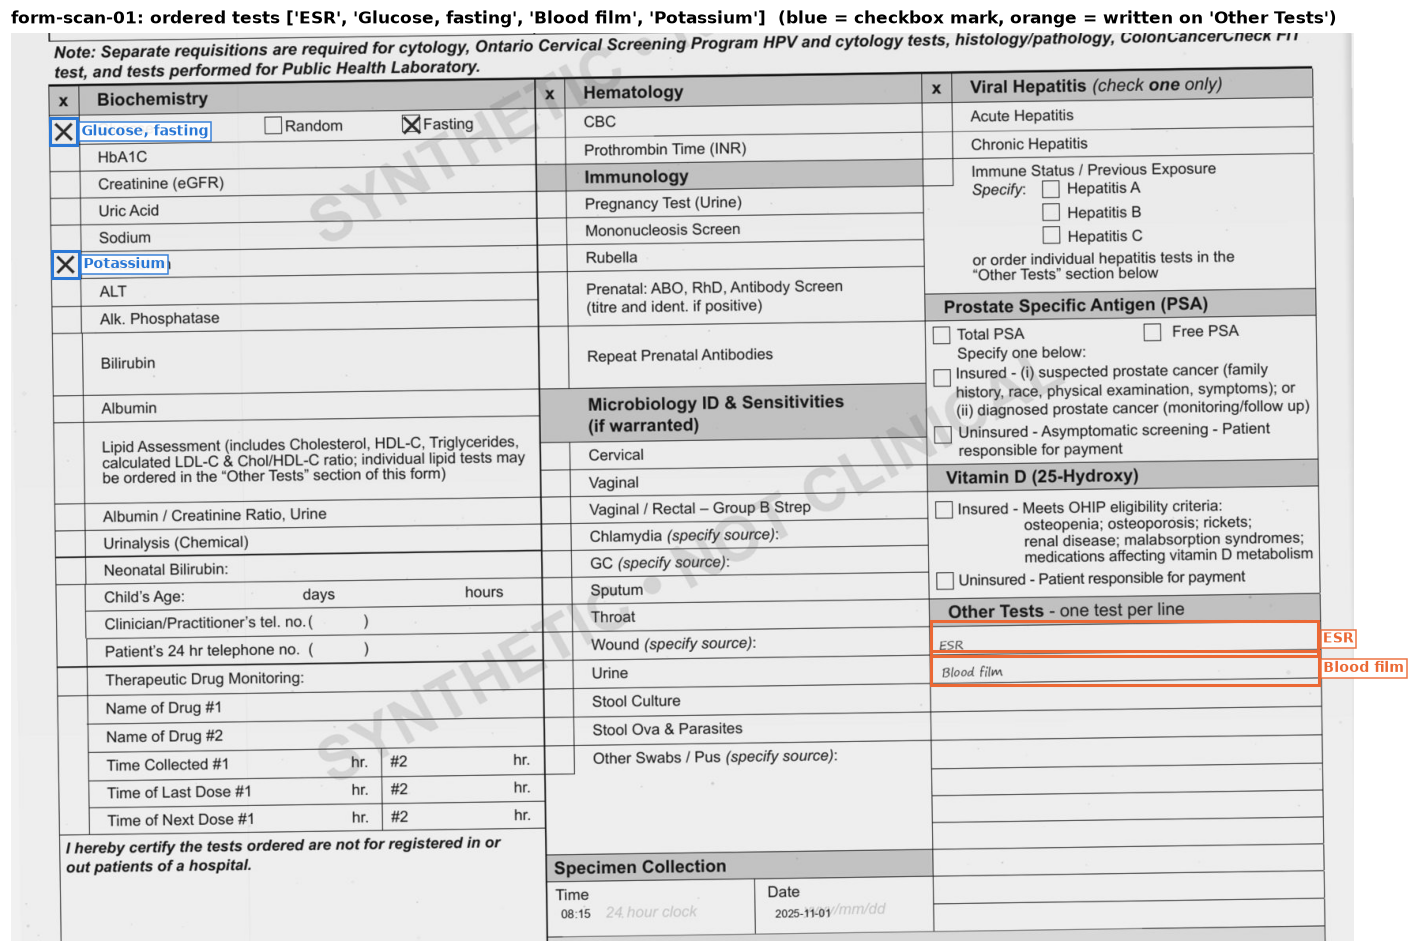

In [5]:
doc = "form-scan-01"
gt = GT[doc]
img = Image.open(DATA / "images" / f"{doc}.jpg")
fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(img.crop((0, 850, 1700, 2000)), extent=(0, 1700, 2000, 850))
for a in gt["annotations"]:
    if a["field_id"].startswith("tests."):
        x, y, w, h = a["bbox"]
        color = PALETTE[0] if a["fill_style"] == "mark" else PALETTE[1]
        ax.add_patch(Rectangle((x - 4, y - 4), w + 8, h + 8, fill=False, lw=2, ec=color))
        ax.text(x + w + 10, y + h / 2, a["field_id"][6:], color=color, fontsize=9, va="center", fontweight="bold",
                bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": color, "pad": 1.5})
ax.set_xlim(0, 1700); ax.set_ylim(2000, 850); ax.axis("off")
ax.set_title(f"{doc}: ordered tests {gt['order']['tests']}  (blue = checkbox mark, orange = written on 'Other Tests')")
plt.tight_layout(); plt.show()

The close-up shows the four ordered tests on form-scan-01. Glucose has an X in the box column and a second X in the "Fasting" box of the same row; together they order one test, fasting glucose. Potassium has an X. ESR and Blood film are written on the first two Other Tests lines in the handwriting-style font. The grid has no printed line for TSH, Ferritin, Vitamin B12, ESR, Reticulocyte count, Blood film or C-reactive protein, so on the official form these seven tests can only be ordered on the Other Tests lines. A reader that checks only the box column would return two of the four tests on this page.

### 2.3 What the ground truth contains
The next cell defines the 31 standard test names the models must use, the 20 scored details and where each is found in the ground truth. It then draws three charts: the number of tests ordered per page, how each ordered test appears on the page, and the fill style of the scored details.

A detail's fill style is `typed`, `handwritten`, `mark` (the sex and coverage boxes) or `empty` (a blank middle name, which a model should return as blank). `handwritten` means the handwriting-style script font; no page has real handwriting. A test is a checkbox test (`checkbox mark`) when it is ordered by a mark in its box, and a written-in test (`written-in`) when it is typed or handwriting-style on an Other Tests line.

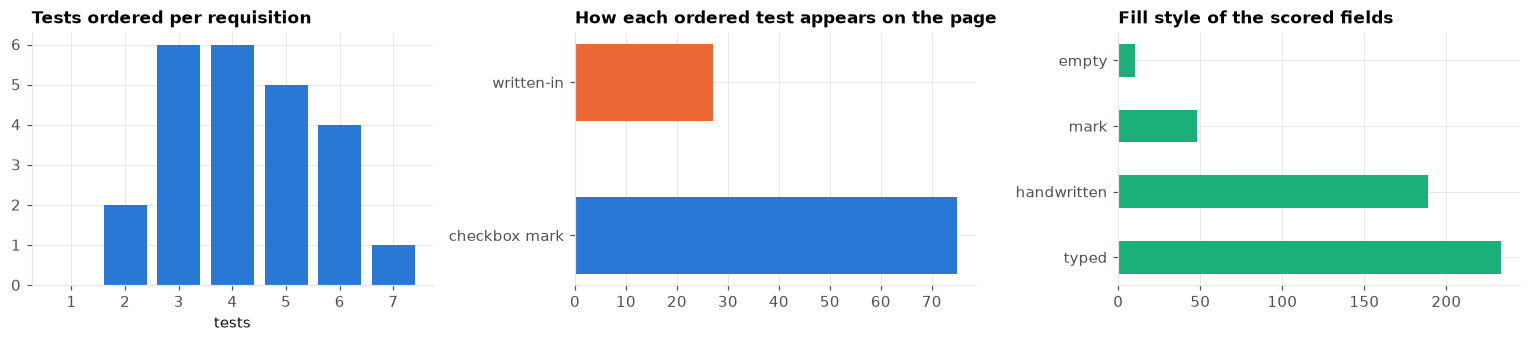

Most frequently ordered tests: {'CBC': 8, 'Vitamin B12': 7, 'TSH': 7, 'Creatinine (eGFR)': 7, 'Potassium': 6, 'Alkaline phosphatase': 6, 'ALT': 6, 'Glucose, fasting': 5}


In [6]:
TEST_VOCAB = [
    "Glucose, fasting", "HbA1C", "Creatinine (eGFR)", "Sodium", "Potassium", "ALT", "Alkaline phosphatase",
    "Bilirubin", "Albumin", "Lipid assessment", "TSH", "Ferritin", "Vitamin B12",
    "CBC", "Prothrombin time (INR)", "ESR", "Reticulocyte count", "Blood film", "Prenatal: ABO, RhD, antibody screen",
    "Urine culture", "Throat culture", "Stool culture", "Chlamydia NAAT", "Gonorrhea NAAT", "Hepatitis B serology",
    "Hepatitis C antibody", "PSA, total", "Vitamin D (25-Hydroxy)", "Pregnancy test (urine)", "Mononucleosis screen",
    "C-reactive protein",
]
FIELDS = [  # (output key, ground-truth annotation id)
    ("patient.last_name", "patient.last_name"), ("patient.first_name", "patient.first_name"),
    ("patient.middle_name", "patient.middle_name"), ("patient.health_number", "patient.health_number"),
    ("patient.version_code", "patient.version_code"), ("patient.date_of_birth", "patient.date_of_birth"),
    ("patient.sex", "patient.sex"), ("patient.phone", "patient.phone"), ("patient.address", "patient.address"),
    ("provider.name", "provider.full_name"), ("provider.clinic_name", "provider.clinic_name"),
    ("provider.address", "provider.address"), ("provider.clinician_number", "provider.provider_id"),
    ("provider.registration_number", "provider.registration_number"), ("provider.urgent_phone", "provider.urgent_phone"),
    ("order.service_date", "order.service_date"), ("order.coverage", "order.coverage"),
    ("order.clinical_information", "order.clinical_information"), ("order.collection_date", "order.collection_date"),
    ("order.collection_time", "order.collection_time"),
]


def gold_fields(gt):
    """{output key: (value, fill style)} for the fields visible on the page."""
    ann = {a["field_id"]: a for a in gt["annotations"]}
    out = {}
    for key, fid in FIELDS:
        if fid == "patient.sex":
            out[key] = (gt["patient"]["sex"], "mark")
        elif fid == "order.coverage":
            out[key] = (gt["order"]["coverage"], "mark")
        elif fid in ann:
            out[key] = (ann[fid]["value"], ann[fid]["fill_style"])
        elif fid == "patient.middle_name":
            out[key] = ("", "empty")
    return out


def gold_tests(gt):
    ann = {a["field_id"][6:]: a["fill_style"] for a in gt["annotations"] if a["field_id"].startswith("tests.")}
    return {t: ("checkbox mark" if ann.get(t) == "mark" else "written-in") for t in gt["order"]["tests"]}


g = pd.DataFrame([{"doc_id": d, "subset": manifest.set_index("doc_id").subset[d], "tests": len(gt["order"]["tests"]),
                   **pd.Series({k: v[1] for k, v in gold_fields(gt).items()}).value_counts().to_dict()}
                  for d, gt in GT.items()]).fillna(0)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
axes[0].hist(g.tests, bins=np.arange(0.5, g.tests.max() + 1.5), color=PALETTE[0], rwidth=0.8)
axes[0].set_title("Tests ordered per requisition"); axes[0].set_xlabel("tests")
src = pd.Series([s for gt in GT.values() for s in gold_tests(gt).values()]).value_counts()
axes[1].barh(src.index, src.values, color=[PALETTE[0], PALETTE[1]][: len(src)], height=0.5)
axes[1].set_title("How each ordered test appears on the page")
styles = g[[c for c in ["typed", "handwritten", "mark", "empty"] if c in g]].sum()
axes[2].barh(styles.index, styles.values, color=PALETTE[2], height=0.5)
axes[2].set_title("Fill style of the scored fields")
plt.tight_layout(); plt.show()
tc = pd.Series([t for gt in GT.values() for t in gt["order"]["tests"]]).value_counts()
print("Most frequently ordered tests:", tc.head(8).to_dict())

Each page orders 2 to 7 tests, 102 in all. 75 are checkbox tests and 27 are written-in tests. All 27 written-in tests are on the official form (18 on scans, 9 on photos), because the Ontario-style layout prints a box for every test in the list. Of the 27, 15 are typed and 12 are in the handwriting-style font. The 480 scored details split into 233 typed, 189 handwriting-style, 48 marks and 10 blanks. The most often ordered tests are CBC (complete blood count, 8 pages), Vitamin B12, TSH and Creatinine (7 each).

With only 27 written-in tests, each one a model misses lowers its written-in recall by almost 4 points. Keep that in mind when reading the split by test type in section 5.2.

## 3. Prompt, models and extraction

### 3.1 The models
| Model | Pinned version | Provider and how called | Size and precision | Settings | Why included |
|---|---|---|---|---|---|
| Claude Opus 5.5 | `claude-opus-5-5` as requested; no dated version recorded | Anthropic, `claude -p` with tools off, image sent as base64 | Not published | Effort medium; CLI default sampling | Hosted model from Anthropic |
| GPT-6.1 | `gpt-6.1-sol` as requested; Codex returned no version, not recorded | OpenAI, `codex exec -i` in a read-only sandbox, image as a file | Not published | Reasoning effort medium; CLI default sampling | Hosted model from OpenAI |
| Muse Wonder | `muse-wonder-full-1.0` as requested; no dated version recorded | Meta, `muse exec --image` with web tools off | Not published | Reasoning effort medium; CLI default sampling | Hosted model from Meta, which also makes Muse Spark Open |
| Qwen3.8 Flash | `qwen/qwen3.8-flash`, undated; no dated version recorded | OpenRouter; all 24 scored replies from Alibaba | Not recorded in `data/` | Temperature 0; 6,000 output tokens, one retry with 20,000; writes reasoning first (median 829 reasoning tokens) | Open-weight vision model from Alibaba's Qwen family |
| Gemma 4 31B | `google/gemma-4-31b-it`, undated; no dated version recorded | OpenRouter; all 24 from ModelRun | 31B parameters (from the name); precision not recorded | Temperature 0; 6,000 output tokens; writes no separate reasoning | Open-weight model from Google that answers without a reasoning step |
| Nemotron 3.5 Super VL | `nvidia/nemotron-3.5-super-vl`, undated; no dated version recorded | OpenRouter; 5 hosts (DeepInfra 13, Crusoe 4, Together 3, Venice 2, CoreWeave 2) | Not recorded in `data/` | As Qwen; median 2,420 reasoning tokens | Open-weight vision model from NVIDIA |
| Muse Spark Open | `meta/muse-spark-open`, undated; no dated version recorded | OpenRouter; 3 hosts (Fireworks 21, Nebius 2, BaseTen 1) | Not recorded in `data/` | As Qwen; median 1,770 reasoning tokens | Open-weight model from Meta; beside Muse Wonder it compares a hosted and an open model from one maker |

Hosts and token counts are counted from `data/cache_openrouter.jsonl` (fields `provider` and `usage.completion_tokens_details.reasoning_tokens`) for the 24 scored replies per model. In the figures and in `data/summary_tests.csv`, GPT-6.1 appears as "GPT-6.1 (Codex)" and the three hosted models are labelled "frontier (CLI)".

### 3.2 The prompt
One prompt goes to every model with the page image. It asks for a single JSON object with the patient (9 details), the clinician, called `provider` (6 details), the order (5 details) and the list of tests. It gives the 31 standard test names, because the form prints shortened names such as "Alk. Phosphatase" or "Throat". It also states the one rule a lab clerk would be told: a test counts if its box, or one of its eligibility boxes, is marked, or if it is written on an Other Tests line. The prompt is in the code cell below section 3.3.

A simpler prompt would ask for "the tests on this form" with no list and no rule. Scoring would then depend on matching free-text names, and a low score could mean a model did not know the form's conventions rather than that it misread the page. Giving every model the names and the rule keeps the comparison about reading.

Open-weight models get 6,000 output tokens. Some of them write a long reasoning passage before answering and can use the whole allowance without producing the JSON. Such a reply is retried once with 20,000 tokens, so that running out of room is not scored as a reading error. The hosted models' tools manage their own output length, and none of their replies needed a retry.

### 3.3 Model calls
There is one extraction call per model and page, 7 x 24 = 168 calls, plus a retry for the 8 open-weight replies that used all 6,000 tokens without an answer. No model judges another: each reply is parsed and compared with the ground truth by a fixed program. Calls for one model run in parallel (4 at a time for `claude`, 2 for `codex`, 3 for `muse`, 6 on OpenRouter); no call depends on another model's reply.

```mermaid
flowchart LR
    in["One requisition image + the shared prompt<br/>(24 images)"]
    subgraph cli ["Hosted models: CLI, effort medium"]
        c1["Claude Opus 5.5<br/>claude -p, image as base64"]
        c2["GPT-6.1<br/>codex exec -i, image file"]
        c3["Muse Wonder<br/>muse exec --image, image file"]
    end
    subgraph open ["Open-weight models: OpenRouter, temperature 0"]
        o1["Qwen3.8 Flash, Gemma 4 31B,<br/>Nemotron 3.5 Super VL, Muse Spark Open<br/>up to 6,000 output tokens"]
        o2["Retry once, up to 20,000 output tokens<br/>8 of 96 replies: Muse Spark Open 4,<br/>Qwen3.8 Flash 2, Nemotron 3.5 Super VL 2"]
        o1 -->|"no JSON and all 6,000 tokens used"| o2
    end
    r["Reply: JSON with patient, provider, order, tests"]
    s["Fixed scoring against the ground truth"]
    in --> c1
    in --> c2
    in --> c3
    in --> o1
    c1 --> r
    c2 --> r
    c3 --> r
    o1 --> r
    o2 --> r
    r --> s
```

The next cell defines the prompt, runs every model on every page (from the cache) and counts, for each model, the replies that contain a readable JSON object and the replies that needed the retry.

In [7]:
PROMPT = """You are reading a scanned or photographed Ontario laboratory requisition.
Extract what is written or marked on the page and return JSON only, with exactly these keys:

{
  "patient": {"last_name": "", "first_name": "", "middle_name": "", "health_number": "", "version_code": "",
              "date_of_birth": "YYYY-MM-DD", "sex": "M or F", "phone": "", "address": "street, city, province postal code"},
  "provider": {"name": "", "clinic_name": "", "address": "", "clinician_number": "", "registration_number": "",
               "urgent_phone": ""},
  "order": {"service_date": "YYYY-MM-DD", "coverage": "OHIP / insured | third party / uninsured | WSIB",
            "clinical_information": "", "collection_date": "YYYY-MM-DD", "collection_time": "HH:MM"},
  "tests": ["..."]
}

Rules:
- Copy values exactly as written. Use "" for a field that is blank on the page.
- "tests" lists every ordered test, using only names from this list:
  """ + "; ".join(TEST_VOCAB) + """
- A test is ordered if its checkbox is marked, if one of its eligibility boxes is marked (e.g. the insured or
  uninsured box under Vitamin D or PSA), or if it is written on an "Other Tests" line. Do not list unmarked tests.
- The page may be rotated or photographed at an angle."""

ALL_MODELS = {**{k: ("cli",) + v for k, v in CLI_MODELS.items()}, **{k: ("openrouter", v) for k, v in OPEN_MODELS.items()}}


def extract(model_name, doc_id):
    kind, *spec = ALL_MODELS[model_name]
    path = DATA / "images" / f"{doc_id}.jpg"
    if kind == "cli":
        backend, model, effort = spec
        out = ask_cli(backend, model, PROMPT, images=[path], effort=effort)
    else:
        out = ask_openrouter(spec[0], PROMPT, path)
        if parse_json(out.get("text")) is None and (out.get("usage") or {}).get("completion_tokens", 0) >= 6000:
            # a reasoning model spent the whole budget thinking: retry once with a larger budget
            out = {**ask_openrouter(spec[0], PROMPT, path, max_tokens=20000), "retried_long": True}
    return {"doc_id": doc_id, "model": model_name, "raw": out.get("text"), "parsed": parse_json(out.get("text")),
            "retried_long": out.get("retried_long", False),
            "error": out.get("error"), "latency_s": out.get("latency_s"),
            "cost": (out.get("usage") or {}).get("cost"), "list_cost_usd": out.get("list_cost_usd")}


runs = []
for name, (kind, *spec) in ALL_MODELS.items():
    w = WORKERS["openrouter"] if kind == "openrouter" else WORKERS[spec[0]]
    runs += pmap(lambda d: extract(name, d), manifest.doc_id, w)
runs = pd.DataFrame(runs)
runs["ok"] = runs.parsed.notna()
print(runs.groupby("model").agg(parsed=("ok", "sum"), documents=("ok", "count"),
                                retried_with_larger_budget=("retried_long", "sum")).to_string())

                       parsed  documents  retried_with_larger_budget
model                                                               
Claude Opus 5.5            24         24                           0
GPT-6.1 (Codex)            24         24                           0
Gemma 4 31B                24         24                           0
Muse Spark Open            23         24                           4
Muse Wonder                24         24                           0
Nemotron 3.5 Super VL      24         24                           2
Qwen3.8 Flash              24         24                           2


167 of the 168 replies are readable. The one that is not is Muse Spark Open on form-scan-05: its first call used all 6,000 tokens and its retry all 20,000 (11,760 of them reasoning), and neither returned any text. 8 replies needed the retry: 4 from Muse Spark Open and 2 each from Qwen3.8 Flash and Nemotron 3.5 Super VL. 7 of the 8 retries produced a readable reply, and two of those are the source of most of Nemotron's and Qwen's added tests (section 7.3).

Readable does not mean useful. Gemma 4 31B returned the JSON template with every value blank and no tests for the two sideways photos, form-photo-04 and form-photo-06. Those two replies parse and are scored as read. These counts come from `data/cache_openrouter.jsonl` (fields `text` and `usage`).

## 4. Scoring rules and a worked example
Scoring is a fixed program; no model judges another.

Each detail is right or wrong. Text is compared after normalising Unicode, case, spacing and punctuation. Dates are compared as year, month and day; phone numbers and identifiers on their letters and digits only; the collection time as hours and minutes; coverage by its category. **Field accuracy** is the share of a model's 480 details that match exactly. A character similarity between 0 and 1 is also recorded for each wrong value, to separate a misread digit from a blank or a value from the wrong field.

The test list is compared with the ground truth as a set. A listed test that was ordered is **found**; a listed test that was not ordered is **added** (a false positive, FP); an ordered test that is not listed is **missed** (a false negative, FN). A name outside the 31 is counted as added; no model wrote one.

- Precision is found / (found + added): of the tests the model listed, the share that were ordered. Low precision means unnecessary tests.
- Recall is found / (found + missed): of the ordered tests, the share the model listed. Low recall means tests that are never run.
- F1 is 2 x precision x recall / (precision + recall). It is high only when both are high. Higher is better, and 1.00 is perfect.
- The exact test list is the share of pages where the list is exactly right, nothing missing and nothing added.

A small example. On form-scan-01, Gemma 4 31B listed 12 tests: the three it should (Glucose, fasting; Potassium; Blood film) and nine more (HbA1C, Creatinine (eGFR), Sodium, ALT, Alkaline phosphatase, Bilirubin, Albumin, CBC and Prothrombin time (INR)). It left out ESR. So 3 found, 9 added, 1 missed: precision 3/12 = 0.25, recall 3/4 = 0.75, F1 = 2 x 0.25 x 0.75 / 1.00 = 0.375. The clerk would have run 9 unnecessary tests and skipped one.

F1 for a model pools every page: found, added and missed are summed over its 24 pages before the formula is applied.

A reply is unreadable when the parser finds no JSON object with a `patient` key in it. An unreadable reply scores as if every detail were blank and no test were listed, so it counts as missing every ordered test. Section 5 gives scores both on all 24 pages and on readable replies only.

The next cell applies these rules to every reply and saves one row per model, page and detail (`data/scored_fields.csv`) and one row per model, page and test that was ordered or listed (`data/scored_tests.csv`).

In [8]:
def norm_text(s):
    s = unicodedata.normalize("NFKC", str(s or "")).lower()
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", s)).strip()


def norm_field(key, v):
    v = "" if v is None else str(v)
    if key.endswith(("phone", "health_number", "clinician_number", "registration_number", "version_code")):
        return re.sub(r"[^0-9a-z]", "", v.lower())
    if key.endswith(("date", "date_of_birth")):
        digits = re.findall(r"\d+", v)
        return "-".join(digits) if len(digits) == 3 else v.strip()
    if key.endswith("collection_time"):
        m = re.search(r"(\d{1,2})\s*[:h.]\s*(\d{2})", v)
        return f"{int(m.group(1)):02d}:{m.group(2)}" if m else v.strip()
    if key.endswith("coverage"):
        t = v.lower()
        return "ohip" if "ohip" in t else "wsib" if "wsib" in t else "third" if "third" in t or "uninsured" in t else t
    if key.endswith("sex"):
        return v.strip().upper()[:1]
    return norm_text(v)


def get_path(d, dotted):
    for part in dotted.split("."):
        d = d.get(part) if isinstance(d, dict) else None
    return d


field_rows, test_rows = [], []
for r in runs.itertuples():
    gt = GT[r.doc_id]
    pred = r.parsed if isinstance(r.parsed, dict) else {}
    for key, (gold, style) in gold_fields(gt).items():
        p, g_ = norm_field(key, get_path(pred, key)), norm_field(key, gold)
        field_rows.append({"model": r.model, "doc_id": r.doc_id, "field": key, "fill_style": style, "gold": gold,
                           "pred": get_path(pred, key), "exact": p == g_,
                           "similarity": SequenceMatcher(None, p, g_).ratio() if (p or g_) else 1.0})
    gold_t = gold_tests(gt)
    pred_t = {t.strip() for t in (pred.get("tests") or []) if isinstance(t, str)}
    for t in set(gold_t) | pred_t:
        test_rows.append({"model": r.model, "doc_id": r.doc_id, "test": t, "gold": t in gold_t, "pred": t in pred_t,
                          "source": gold_t.get(t, "not ordered")})
fields = pd.DataFrame(field_rows).merge(manifest[["doc_id", "subset"]], on="doc_id")
tests = pd.DataFrame(test_rows).merge(manifest[["doc_id", "subset"]], on="doc_id")
fields.to_csv(DATA / "scored_fields.csv", index=False)
tests.to_csv(DATA / "scored_tests.csv", index=False)
print(f"{len(fields):,} field judgements, {len(tests):,} test judgements")

3,360 field judgements, 876 test judgements


The 3,360 detail checks are 7 models x 24 pages x 20 details. The 876 test checks are the 714 ordered tests (102 per model) plus the 162 tests that models listed although they were not ordered.

### 4.1 Worked example: one page from image to score
This is form-scan-01, the page in the close-up of section 2.2, as Claude Opus 5.5 read it.

The page orders four tests: fasting glucose (the X beside Glucose and the X in the Fasting box), Potassium (an X), and ESR and Blood film, written on the first two Other Tests lines in the handwriting-style font. The ground truth (`data/ground_truth/form-scan-01.json`, field `order.tests`) lists them as Glucose, fasting; Potassium; ESR; Blood film. Among the 20 details, the patient's last name, address, the clinician's name and both clinician numbers are in the handwriting-style font, and the date of birth, 1962-02-16, is typed.

Claude's reply came back in 9.4 seconds as a JSON object inside a code fence, which the parser removes. Its test list:

```json
"tests": ["Glucose, fasting", "Potassium", "ESR", "Blood film"]
```

Scoring compares this list with the ground truth as two sets. All four ordered tests are listed and nothing else is: 4 found, 0 added, 0 missed. Each detail is compared after normalising, so "688 Training Data Trail, Peterborough, ON Z7Z 2Z5" matches the ground truth's version with two spaces before the postal code. All 20 details match. form-scan-01 is one of Claude's 24 exact test lists and one of its 19 pages with no error of any kind. On the same page Gemma 4 31B scored precision 0.25 and recall 0.75, the example in the rules above.

## 5. Results: ordered tests

### 5.1 Overall test extraction
The next cell computes, for each model, the found (TP), added (FP) and missed (FN) counts over all 24 pages, precision, recall and F1, the share of pages with the exact test list, and a 95% interval for F1 from 1,000 resamples of the 24 pages. The `kind` column labels the three hosted models `frontier (CLI)` and the others `open weights`, and GPT-6.1 appears as "GPT-6.1 (Codex)". Compare F1 and the exact-list share across models, and look at whether a model's errors are added tests or missed tests: they cost a lab different things.

In [9]:
def prf(df):
    tp = (df.gold & df.pred).sum(); fp = (~df.gold & df.pred).sum(); fn = (df.gold & ~df.pred).sum()
    p = tp / (tp + fp) if tp + fp else np.nan; r = tp / (tp + fn) if tp + fn else np.nan
    return pd.Series({"precision": p, "recall": r, "F1": 2 * p * r / (p + r) if p + r else 0.0, "TP": tp, "FP": fp, "FN": fn})


def doc_exact(df):
    return df.groupby("doc_id").apply(lambda x: bool((x.gold == x.pred).all())).mean()


def boot_f1(df, n=1000, seed=0):
    docs = df.doc_id.unique(); rng = np.random.default_rng(seed); groups = dict(tuple(df.groupby("doc_id")))
    vals = [prf(pd.concat([groups[d] for d in rng.choice(docs, len(docs))]))["F1"] for _ in range(n)]
    return np.percentile(vals, [2.5, 97.5])


order = list(ALL_MODELS)
summary = pd.DataFrame({m: prf(tests[tests.model == m]) for m in order}).T
summary["all tests right"] = [doc_exact(tests[tests.model == m]) for m in order]
summary["F1 95% CI"] = [f"[{lo:.2f}, {hi:.2f}]" for lo, hi in (boot_f1(tests[tests.model == m]) for m in order)]
summary["kind"] = ["frontier (CLI)" if ALL_MODELS[m][0] == "cli" else "open weights" for m in order]
summary.to_csv(DATA / "summary_tests.csv")
summary.style.format({"precision": "{:.1%}", "recall": "{:.1%}", "F1": "{:.3f}", "all tests right": "{:.0%}",
                      "TP": "{:.0f}", "FP": "{:.0f}", "FN": "{:.0f}"}) \
    .background_gradient(subset=["F1", "all tests right"], cmap="Blues", vmin=0, vmax=1)

,precision,recall,F1,TP,FP,FN,all tests right,F1 95% CI,kind
Claude Opus 5.5,100.0%,100.0%,1.000,102,0,0,100%,"[1.00, 1.00]",frontier (CLI)
GPT-6.1 (Codex),100.0%,99.0%,0.995,101,0,1,96%,"[0.98, 1.00]",frontier (CLI)
Muse Wonder,97.1%,100.0%,0.986,102,3,0,96%,"[0.96, 1.00]",frontier (CLI)
Qwen3.8 Flash,75.4%,84.3%,0.796,86,28,16,50%,"[0.63, 0.93]",open weights
Gemma 4 31B,42.8%,66.7%,0.521,68,91,34,17%,"[0.42, 0.63]",open weights
Nemotron 3.5 Super VL,71.4%,93.1%,0.809,95,38,7,75%,"[0.62, 0.97]",open weights
Muse Spark Open,97.9%,90.2%,0.939,92,2,10,83%,"[0.85, 1.00]",open weights


Claude Opus 5.5 found all 102 ordered tests and added none (F1 1.00, exact list on 24 of 24 pages). GPT-6.1 missed 1 (F1 0.995) and Muse Wonder added 3 (F1 0.986), both with the exact list on 23 pages. Between them the hosted models made 4 test errors in 72 replies, all on phone photos: GPT-6.1 missed Vitamin B12 on form-photo-02, and Muse Wonder added CBC, Hepatitis B serology and Hepatitis C antibody on form-photo-04. They are at the ceiling of this test, their intervals overlap almost entirely, and it cannot say which of the three reads test lists best.

Claude's interval of [1.00, 1.00] carries no information: when a model is perfect on every page, every resample is perfect too. A better statement is that 0 misses in 102 ordered tests is consistent with a true miss rate of up to 3.6% (the upper end of a 95% Wilson interval).

Among the open-weight models, Muse Spark Open is best (F1 0.939, exact list on 20 of 24), then Nemotron 3.5 Super VL (0.809, 18), Qwen3.8 Flash (0.796, 12) and Gemma 4 31B (0.521, 4). Gemma added 91 tests and found 68. On readable replies only, Muse Spark Open found 92 of 96 ordered tests, added 2 and had the exact list on 20 of 23 pages: F1 0.968. Without its two blank replies, Gemma's F1 is 0.535. Neither change alters the order of the seven models.

The next cell draws the same numbers. In the left panel, whose title is a colour key, blue bars are the three hosted models and green bars the four open-weight models; each bar is a model's F1, the black tick its precision and the orange dot its recall. The white label inside the bar rounds F1 to two decimals, so GPT-6.1's 0.995 shows as "1.00". The right panel is the share of the 24 pages with the exact test list.

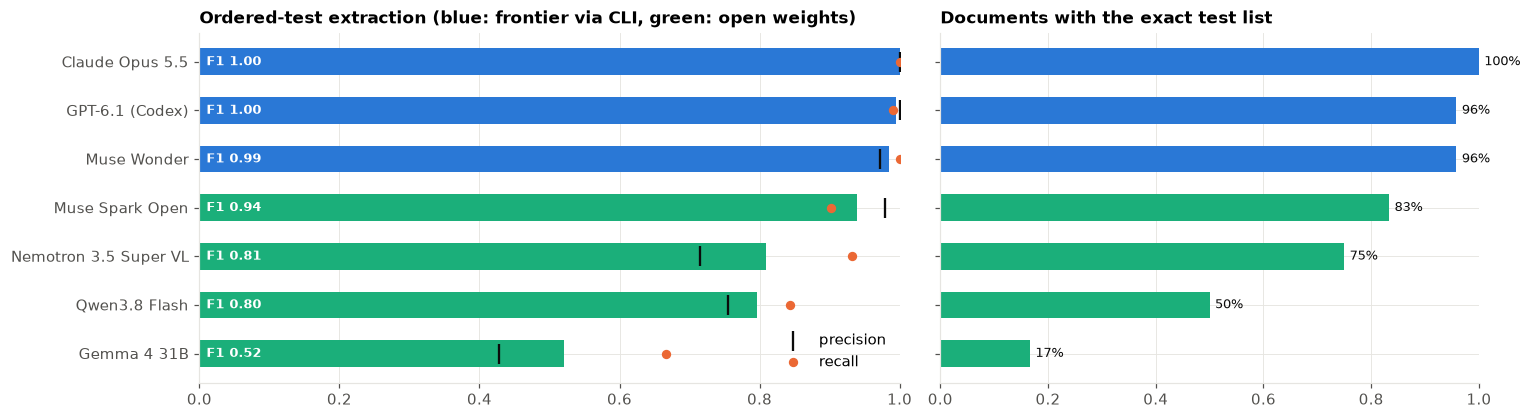

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9), gridspec_kw={"width_ratios": [1.3, 1]})
s = summary.sort_values("F1")
colors = [PALETTE[0] if k == "frontier (CLI)" else PALETTE[2] for k in s.kind]
axes[0].barh(s.index, s.F1.astype(float), color=colors, height=0.55)
axes[0].scatter(s.precision.astype(float), s.index, marker="|", s=160, color=INK, label="precision", zorder=3)
axes[0].scatter(s.recall.astype(float), s.index, marker="o", s=26, color=PALETTE[1], label="recall", zorder=3)
for y, v in enumerate(s.F1.astype(float)):
    axes[0].text(0.01, y, f"F1 {v:.2f}", va="center", color="white", fontsize=8.5, fontweight="bold")
axes[0].set_xlim(0, 1); axes[0].legend(loc="lower right")
axes[0].set_title("Ordered-test extraction (blue: frontier via CLI, green: open weights)")
axes[1].barh(s.index, s["all tests right"].astype(float), color=colors, height=0.55)
axes[1].set_xlim(0, 1); axes[1].set_yticklabels([]); axes[1].set_title("Documents with the exact test list")
for y, v in enumerate(s["all tests right"].astype(float)):
    axes[1].text(v + 0.01, y, f"{v:.0%}", va="center", color=INK, fontsize=8.5)
plt.tight_layout(); fig.savefig(FIG / "tests_overall.png"); plt.show()

Among the open-weight models the tick and the dot tell different stories. Muse Spark Open's precision (0.98) is level with the hosted models'; it falls short on recall (0.90), and 6 of its 10 misses are the 6 tests on its unreadable reply. Nemotron and Qwen have the reverse problem: their recall is 0.93 and 0.84 but their precision is 0.71 and 0.75, because of the added tests. Gemma is low on both. The exact-list panel spreads the open models further apart than F1 does: Qwen's 0.80 F1 comes with the exact list on only half the pages.

### 5.2 Checkbox tests versus written-in tests, and scans versus phone photos
The next cell draws two heat maps; darker blue is better and each cell prints its value. The left map splits recall by how the test appears on the page: 75 ordered tests are checkbox tests and 27 are written in. Precision cannot be split this way, because an added test has no position on the page. The right map gives test F1 for each subset of pages: 32 ordered tests on phone photos, 47 on official-form scans and 23 on Ontario-style scans.

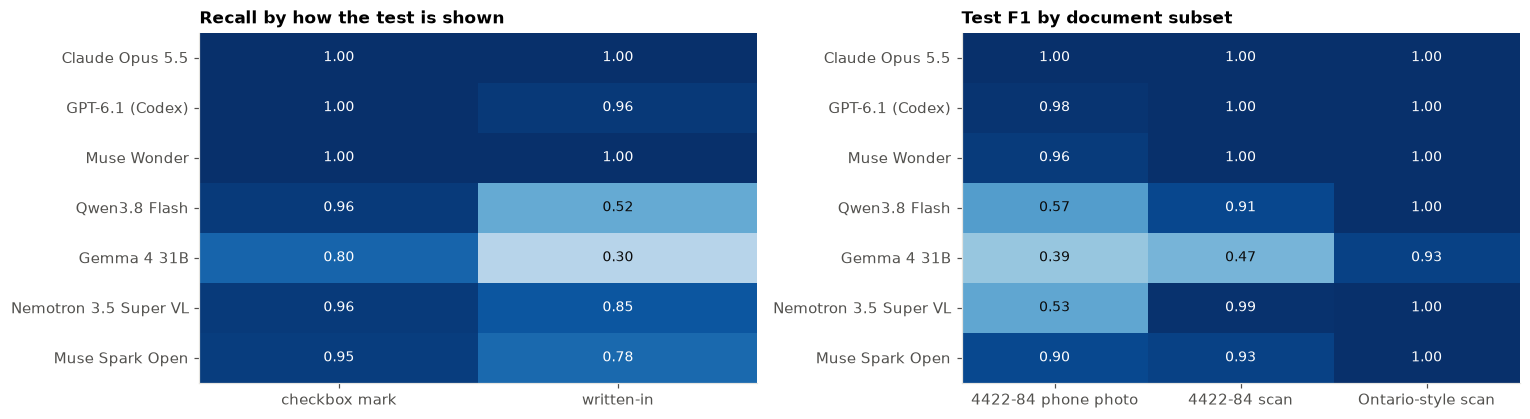

In [11]:
rec = tests[tests.gold].groupby(["model", "source"]).pred.mean().unstack()[["checkbox mark", "written-in"]].reindex(order)
f1_sub = tests.groupby(["model", "subset"]).apply(lambda d: prf(d)["F1"]).unstack().reindex(order)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
for ax, tbl, title in [(axes[0], rec, "Recall by how the test is shown"), (axes[1], f1_sub, "Test F1 by document subset")]:
    im = ax.imshow(tbl.values.astype(float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(tbl.shape[1]), tbl.columns); ax.set_yticks(range(len(tbl)), tbl.index); ax.grid(False)
    for i in range(tbl.shape[0]):
        for j in range(tbl.shape[1]):
            v = tbl.values[i, j]
            ax.text(j, i, "n/a" if pd.isna(v) else f"{v:.2f}", ha="center", va="center",
                    color="white" if (not pd.isna(v) and v > 0.6) else INK, fontsize=9)
    ax.set_title(title)
plt.tight_layout(); fig.savefig(FIG / "tests_by_source_subset.png"); plt.show()

Written-in tests separate the open models from the hosted ones. Qwen found 72 of 75 checkbox tests but 14 of 27 written-in tests; Nemotron 72 and 23; Muse Spark Open 71 and 21; Gemma 60 and 8. Together the open models found 66 of 108 written-in tests against 275 of 300 checkbox tests, while the hosted models found 80 of 81 written-in tests. For Qwen the weakness is about the Other Tests lines rather than the font: it found 8 of the 12 handwriting-style written-in tests and 6 of the 15 typed ones.

The right map shows the phone-photo drop. Every model except Gemma scored 1.00 on the Ontario-style scans, where all 23 ordered tests are checkbox tests in short lists. Nemotron scored 0.99 on official-form scans and 0.53 on phone photos; Qwen 0.91 and 0.57. Those photo scores rest mostly on one page each. Nemotron's reply for form-photo-02 listed all 31 test names in the prompt, 28 of them not ordered: 28 of its 38 added tests. Qwen's reply for form-photo-06 listed 24 names, 22 of them not ordered: 22 of its 28 (section 7.3 shows both). Without those two pages, Nemotron's F1 on the other 7 phone photos is 0.73 and Qwen's 0.76, and their F1 over all remaining pages is 0.92 and 0.88. So the photo drop is mostly one reply each, but even without it both models are weaker on photos than on scans. These recounts use `data/scored_tests.csv` with the named page removed.

### 5.3 Tests that are hard to find
The next cell computes recall for each test over every page that ordered it, for each model, with the number of pages in brackets after the test's name. Darker blue is higher recall. Two kinds of test are worth watching: tests that need two marks (Glucose with Fasting) or an eligibility box, where knowledge of the layout matters, and tests the official form does not print, which must be written in.

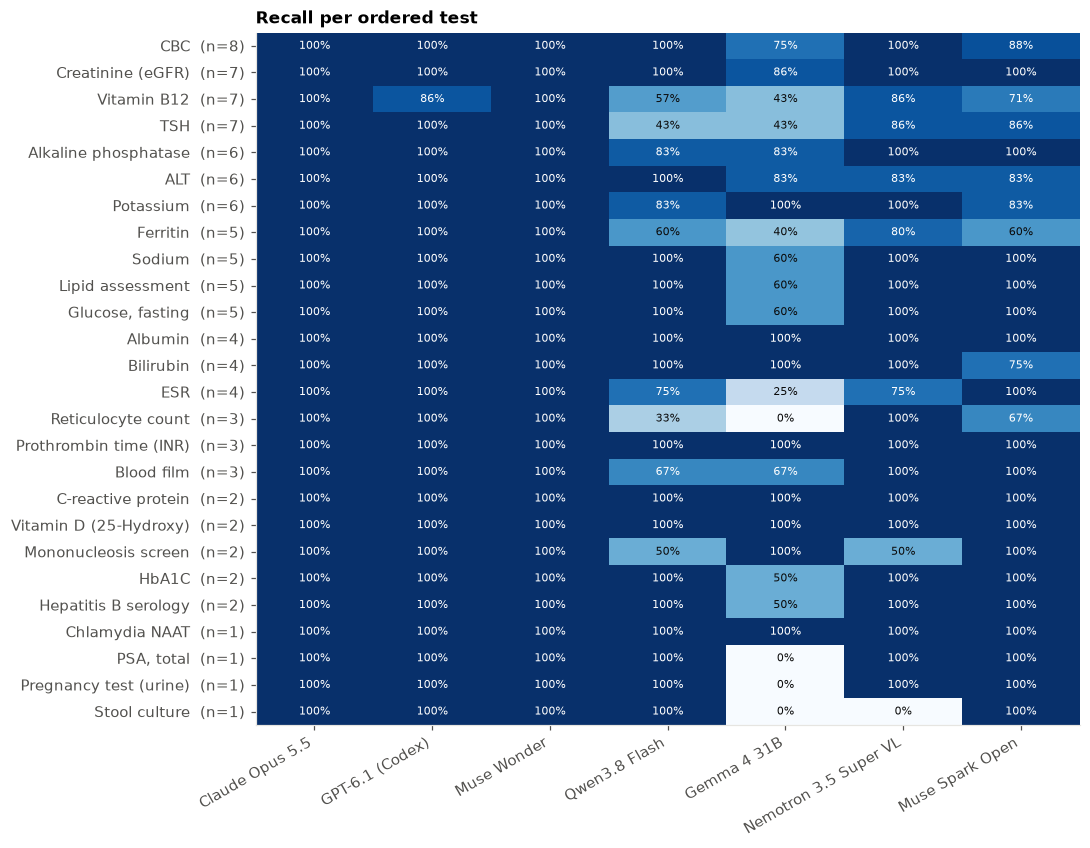

In [12]:
per_test = tests[tests.gold].groupby(["test", "model"]).pred.mean().unstack().reindex(columns=order)
per_test["n"] = tests[tests.gold & (tests.model == order[0])].groupby("test").size()
per_test = per_test.sort_values("n", ascending=False)
fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * len(per_test))))
vals = per_test[order].values.astype(float)
ax.imshow(vals, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(order)), order, rotation=30, ha="right")
ax.set_yticks(range(len(per_test)), [f"{t}  (n={int(n)})" for t, n in zip(per_test.index, per_test.n)]); ax.grid(False)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        if not np.isnan(vals[i, j]):
            ax.text(j, i, f"{vals[i, j]:.0%}", ha="center", va="center", fontsize=7.5, color="white" if vals[i, j] > 0.6 else INK)
ax.set_title("Recall per ordered test")
plt.tight_layout(); plt.show()

Pooled over the seven models, the hardest tests are the ones the official form has no box for: Reticulocyte count was found in 15 of 21 model-page pairs, Ferritin 27 of 35, Vitamin B12 38 of 49 and TSH 39 of 49 (counted from `data/scored_tests.csv`). The two-mark test, fasting glucose, was found in 33 of 35 pairs; only Gemma missed it, twice. Reading the two marks on the Glucose row as one test was not a problem for the other six models.

### 5.4 Added tests
The next cell counts, for each model and test, how often the test was listed on a page that did not order it, and prints the 12 most frequent pairs.

In [13]:
fp = tests[~tests.gold & tests.pred].groupby(["model", "test"]).size().rename("false positives").reset_index()
print("Most frequent false positives (test listed but not ordered):")
fp.sort_values("false positives", ascending=False).head(12)

Most frequent false positives (test listed but not ordered):


,model,test,false positives
8,Gemma 4 31B,HbA1C,8
16,Gemma 4 31B,Prothrombin time (INR),8
5,Gemma 4 31B,Creatinine (eGFR),7
0,Gemma 4 31B,ALT,7
17,Gemma 4 31B,Sodium,7
7,Gemma 4 31B,"Glucose, fasting",7
2,Gemma 4 31B,Alkaline phosphatase,6
4,Gemma 4 31B,CBC,6
13,Gemma 4 31B,Potassium,6
3,Gemma 4 31B,Bilirubin,5


All 12 of the most frequent pairs are Gemma 4 31B's, and they are the printed rows of the official form's Biochemistry column (HbA1C, Creatinine, Sodium, Glucose, ALT, Alkaline phosphatase, Potassium, Bilirubin, Albumin, Lipid assessment) and the first two rows of its Hematology column (CBC, Prothrombin time). Gemma adds the same block of names on page after page (section 7.4). Nemotron's 38 and Qwen's 28 added tests do not reach this list, because most of them come from one long reply each, which added each name once.

## 6. Results: patient, clinician and order details

### 6.1 Field accuracy
The next cell draws exact-match accuracy for each of the 20 details and each model, after the normalisation in section 4. Each row is one detail, named as in the output format (`patient.date_of_birth` is the patient's date of birth, `provider.urgent_phone` the clinician's urgent-results phone, `order.coverage` the insurance box). Each cell is the share of the model's 24 pages on which that detail matched. The bottom row, below the white line, pools all 480 details. Darker is better. Look at the date of birth, which the official form splits into year, month and day boxes, and at the addresses and phone numbers.

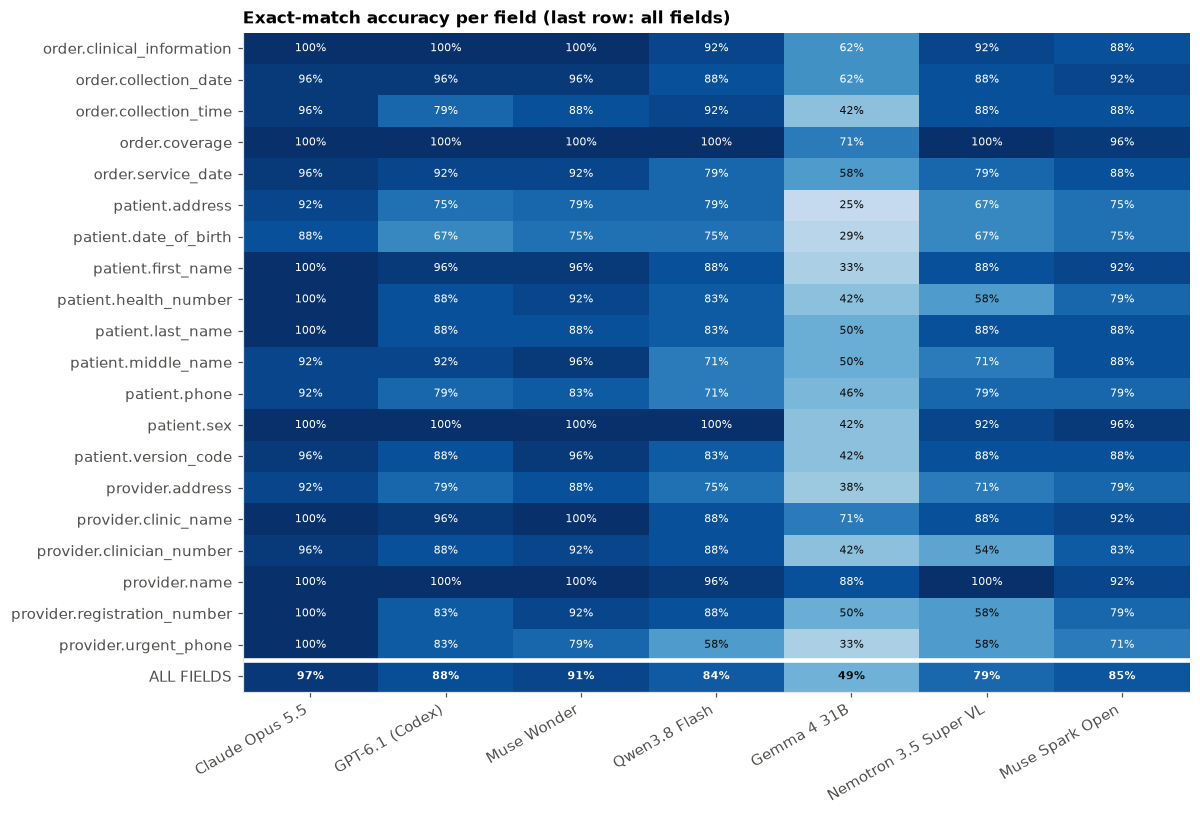

In [14]:
facc = fields.pivot_table(index="field", columns="model", values="exact", aggfunc="mean")[order]
facc.loc["ALL FIELDS"] = fields.groupby("model").exact.mean()[order]
fig, ax = plt.subplots(figsize=(11, 7.5))
vals = facc.values.astype(float)
ax.imshow(vals, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(order)), order, rotation=30, ha="right"); ax.set_yticks(range(len(facc)), facc.index); ax.grid(False)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        ax.text(j, i, f"{vals[i, j]:.0%}", ha="center", va="center", fontsize=7.5,
                color="white" if vals[i, j] > 0.6 else INK, fontweight="bold" if i == len(facc) - 1 else "normal")
ax.axhline(len(facc) - 1.5, color="white", lw=3)
ax.set_title("Exact-match accuracy per field (last row: all fields)")
plt.tight_layout(); fig.savefig(FIG / "fields_heatmap.png"); plt.show()

Claude Opus 5.5 copied 464 of 480 details exactly (96.7%), Muse Wonder 439 (91.5%), GPT-6.1 424 (88.3%), Muse Spark Open 409 (85.2%), Qwen 402 (83.8%), Nemotron 377 (78.5%) and Gemma 234 (48.8%), counted from `data/scored_fields.csv`, column `exact`. On readable replies only, Muse Spark Open copied 409 of 460 (88.9%), which puts it 0.6 points above GPT-6.1; that is the one place where leaving out the unreadable reply changes the order of two models.

Across all models the hardest details were the date of birth (right in 114 of 168 replies, 68%), the clinician's urgent-results phone (116, 69%), the patient's address (118, 70%) and the clinician's address (125, 74%). The easiest were the clinician's name (162, 96%) and the coverage box (160, 95%). Gemma's column is pale almost everywhere; 121 of its 246 wrong details are blanks, including the 40 from its two empty replies.

### 6.2 Typed versus handwriting-style details, and near misses
Exact match is strict: one wrong digit in a health number makes a wrong record. The next cell draws two panels. On the left, each model has three bars: accuracy on typed details, on handwriting-style details (`handwritten`) and on marks. On the right, the bar is the median character similarity between a wrong value and the right one; a value near 1 means the misses are near misses, a value near 0 means they are mostly blanks.

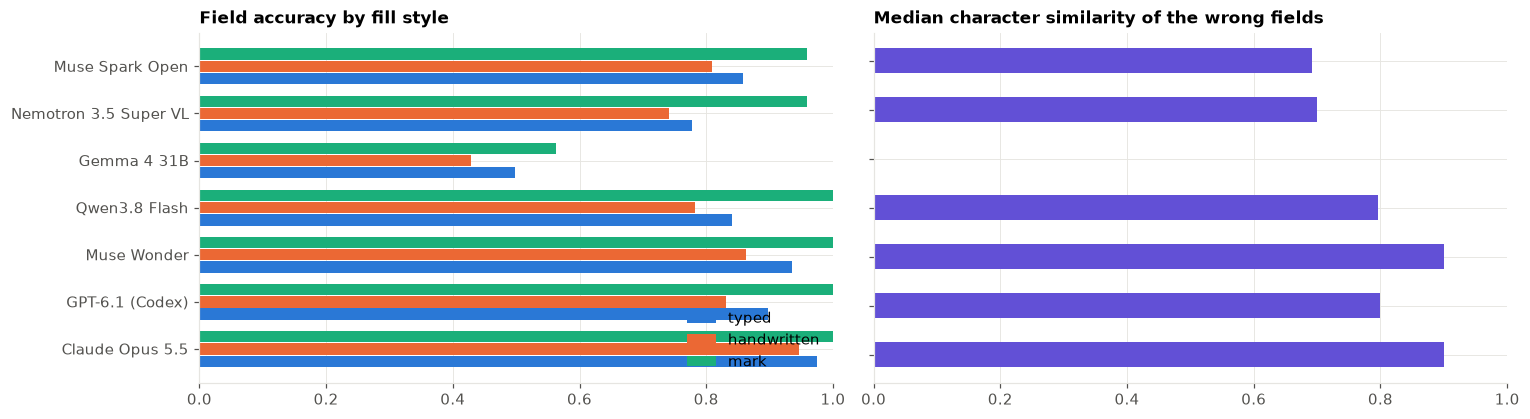

In [15]:
by_style = fields[fields.fill_style.isin(["typed", "handwritten", "mark"])].pivot_table(
    index="model", columns="fill_style", values="exact", aggfunc="mean").reindex(order)
miss_sim = fields[~fields.exact].groupby("model").similarity.median().reindex(order)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
y = np.arange(len(order))
for k, col in enumerate([c for c in ["typed", "handwritten", "mark"] if c in by_style]):
    axes[0].barh(y + (k - 1) * 0.26, by_style[col], height=0.24, color=PALETTE[k], label=col)
axes[0].set_yticks(y, order); axes[0].set_xlim(0, 1); axes[0].legend(loc="lower right")
axes[0].set_title("Field accuracy by fill style")
axes[1].barh(order, miss_sim.values, color=PALETTE[6], height=0.5)
axes[1].set_xlim(0, 1); axes[1].set_yticklabels([])
axes[1].set_title("Median character similarity of the wrong fields")
plt.tight_layout(); plt.show()

On the left, every model scores lower on handwriting-style details than on typed ones: Claude 94.7% against 97.4%, Muse Wonder 86.2% against 93.6%, GPT-6.1 83.1% against 89.7%. Marks are easy for all but Gemma (27 of 48). On the right, the median similarity of wrong values is 0.9 for Claude and Muse Wonder, 0.8 for GPT-6.1 and Qwen, about 0.7 for Nemotron and Muse Spark Open and 0.0 for Gemma, whose wrong values are mostly blanks.

The font looks like the cause of the hosted models' gaps at first. Splitting by subset, counted from `data/scored_fields.csv` (columns `subset`, `fill_style`, `exact`), shows that the photos matter more than the font:

| Model | Official-form scans: typed | Official-form scans: handwriting-style | Phone photos: typed | Phone photos: handwriting-style | Ontario-style scans: all |
|---|---:|---:|---:|---:|---:|
| Claude Opus 5.5 | 99 / 99 | 77 / 78 | 69 / 75 | 57 / 66 | 104 / 104 |
| GPT-6.1 | 99 / 99 | 74 / 78 | 51 / 75 | 38 / 66 | 104 / 104 |
| Muse Wonder | 99 / 99 | 73 / 78 | 60 / 75 | 45 / 66 | 104 / 104 |
| Muse Spark Open | 86 / 99 | 66 / 78 | 55 / 75 | 42 / 66 | 104 / 104 |
| Qwen3.8 Flash | 94 / 99 | 67 / 78 | 43 / 75 | 36 / 66 | 104 / 104 |
| Nemotron 3.5 Super VL | 87 / 99 | 65 / 78 | 35 / 75 | 30 / 66 | 104 / 104 |
| Gemma 4 31B | 51 / 99 | 35 / 78 | 11 / 75 | 2 / 66 | 98 / 104 |

On scans of the official form, the hosted models missed at most 5 handwriting-style details out of 78. On phone photos all seven models lost accuracy in both fonts: GPT-6.1 fell from 173 of 177 on scans to 89 of 141 on photos. 52 of GPT-6.1's 56 wrong details and 15 of Claude's 16 are on phone photos. On the Ontario-style scans, six models copied all 104 typed and handwriting-style details.

### 6.3 Whole-document view
A page is clean when all 20 details and the test list are right: it could go into the lab system with no correction. The next cell counts each model's errors per page, details and tests added together, and draws each model's 24 pages as shares in four groups: 0 errors (green), 1 error, 2 to 3 errors and 4 or more (red).

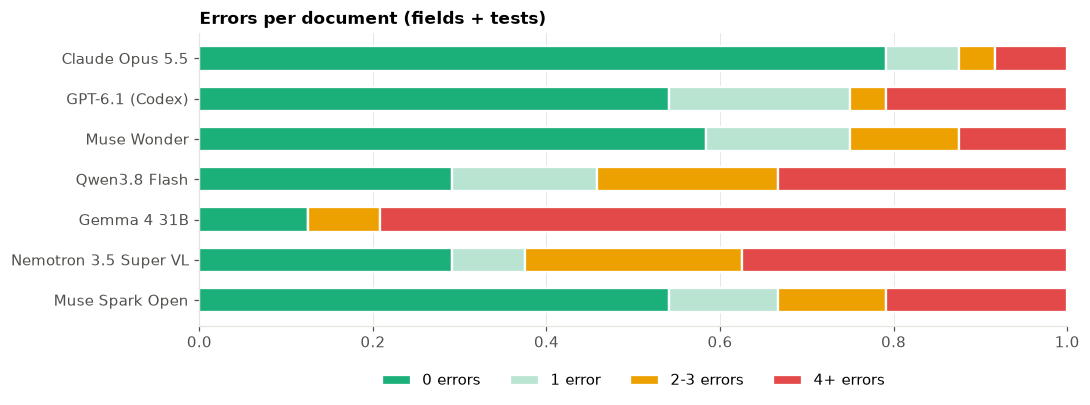

In [16]:
doc_err = fields.groupby(["model", "doc_id"]).exact.apply(lambda s: (~s).sum()).rename("field errors").to_frame()
doc_err["test errors"] = tests.groupby(["model", "doc_id"]).apply(lambda d: int((d.gold != d.pred).sum()))
doc_err["total"] = doc_err.sum(axis=1)
bins = pd.cut(doc_err.total, [-1, 0, 1, 3, 1000], labels=["0 errors", "1 error", "2-3 errors", "4+ errors"])
dist = bins.groupby(level=0).value_counts(normalize=True).unstack().reindex(order)
fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(dist))
for k, col in enumerate(dist.columns):
    ax.barh(dist.index, dist[col], left=left, color=[GOOD, "#b9e4d2", WARN, BAD][k], height=0.6, label=col,
            edgecolor="white", linewidth=1.5)
    left += dist[col].values
ax.set_xlim(0, 1); ax.invert_yaxis(); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Errors per document (fields + tests)")
plt.tight_layout(); fig.savefig(FIG / "errors_per_document.png"); plt.show()

Claude produced 19 clean pages of 24, Muse Wonder 14, GPT-6.1 and Muse Spark Open 13 each, Qwen and Nemotron 7 each and Gemma 3 (counted from `data/scored_fields.csv` and `data/scored_tests.csv`). Claude's five pages with errors are four phone photos and form-scan-10, where its only error is the date of birth. This view is stricter than either score above, and it is closest to the question a lab asks: how many pages need no correction at all.

## 7. Error analysis
The examples in this section were chosen to explain the patterns in sections 5 and 6. Each is identified by page ID and model and can be found in `data/scored_tests.csv` and `data/scored_fields.csv`.

### 7.1 The hardest page
The next cell finds the page with the most errors summed over all models, then draws a box around each ordered test, coloured by whether the best model on F1 (Claude Opus 5.5) and the worst (Gemma 4 31B) found it: green for both, orange for one, red for neither. The title lists the ordered tests as a Python list and the added tests of both models. The page fills only the lower right of the frame, so the marks are small.

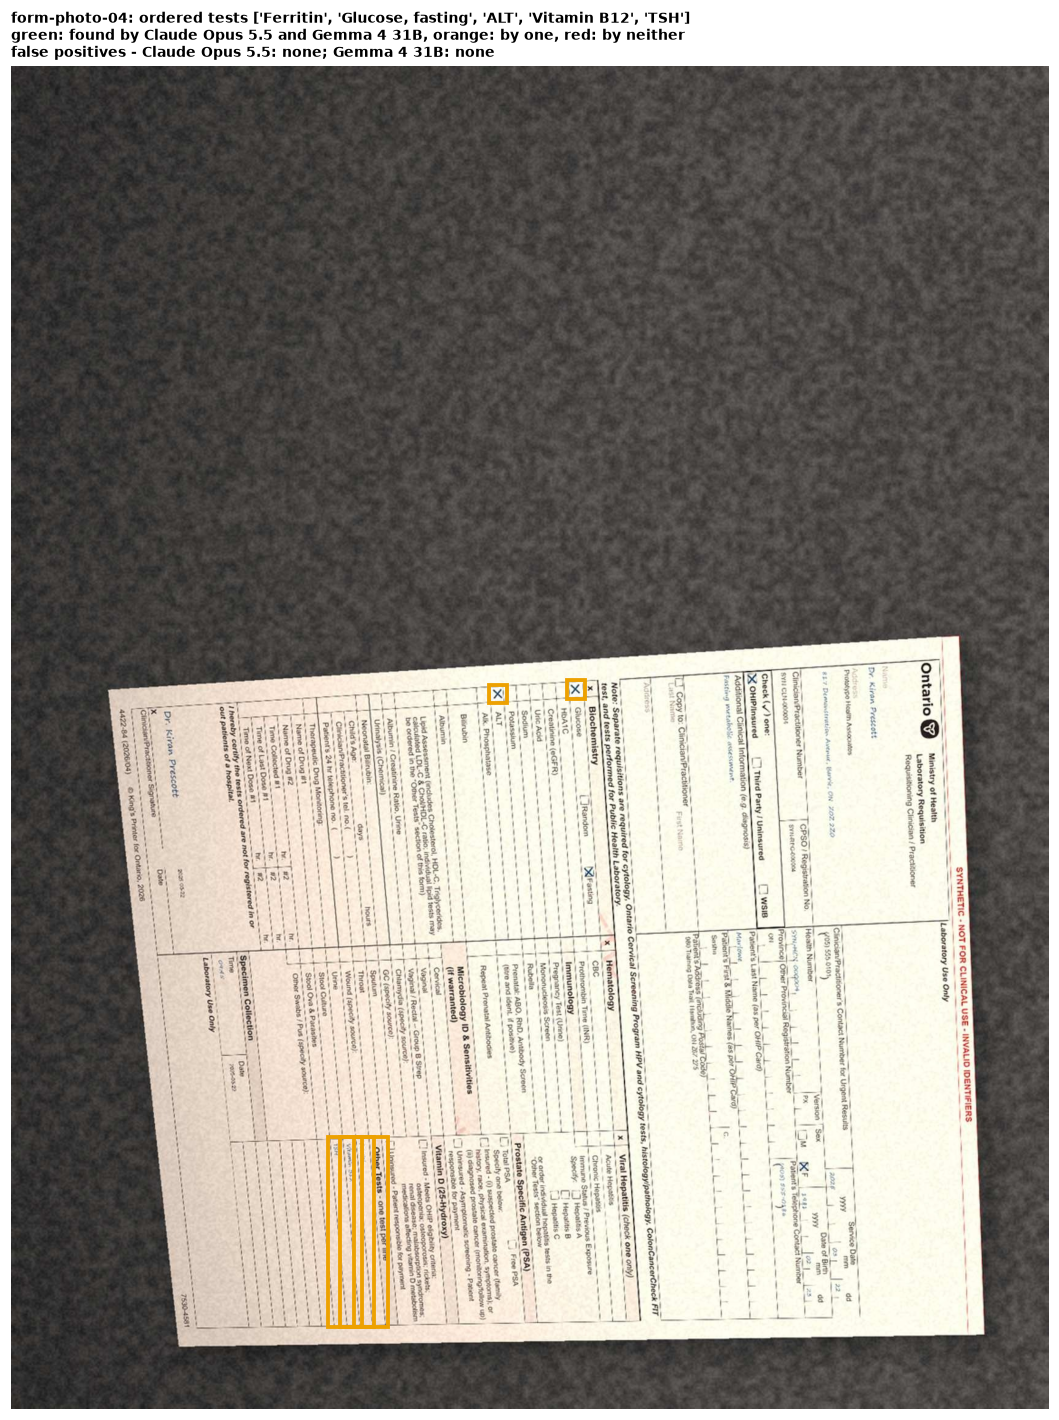

In [17]:
model_f1 = summary.F1.astype(float)
best_m, worst_m = model_f1.idxmax(), model_f1.idxmin()
hard_doc = doc_err.groupby(level=1).total.sum().idxmax()
gt = GT[hard_doc]
found = {m: set(tests[(tests.model == m) & (tests.doc_id == hard_doc) & tests.pred].test) for m in (best_m, worst_m)}
fig, ax = plt.subplots(figsize=(11, 13))
ax.imshow(Image.open(DATA / "images" / f"{hard_doc}.jpg")); ax.axis("off")
for a in gt["annotations"]:
    if a["field_id"].startswith("tests."):
        t = a["field_id"][6:]
        hits = sum(t in found[m] for m in found)
        color = [BAD, WARN, GOOD][hits]
        x, y, w, h = a["bbox"]
        ax.add_patch(Rectangle((x - 6, y - 6), w + 12, h + 12, fill=False, lw=2.5, ec=color))
fps = {m: sorted(found[m] - set(gt["order"]["tests"])) for m in found}
ax.set_title(f"{hard_doc}: ordered tests {gt['order']['tests']}\n"
             f"green: found by {best_m} and {worst_m}, orange: by one, red: by neither\n"
             f"false positives - {best_m}: {fps[best_m] or 'none'}; {worst_m}: {fps[worst_m] or 'none'}",
             fontsize=9, loc="left")
plt.tight_layout(); fig.savefig(FIG / "hardest_document.png"); plt.show()

The hardest page is form-photo-04, a sideways photo compressed to the quality of a messaging app. It holds 129 of the 841 wrong details and test decisions in the study, on 1 page of 24. Claude made 7 of them, GPT-6.1 and Muse Wonder 16 each, and the open models 20 to 25 each. All five boxes are orange because Claude found all five ordered tests and Gemma, whose reply was blank, found none.

Claude's reply on this page is a typical success with a limit. It found all five tests, including the three in the handwriting-style font on the Other Tests lines (Ferritin, Vitamin B12, TSH), but made 7 of its 16 detail errors here: the service and collection dates as 2026-03-22 for 2025-03-22, the date of birth as 1983-02-25 for 1981-02-23, the phone ending 0184 for 0186, the house number 960 for 980 and two more. A clerk would get the right tests and a patient record that does not match. GPT-6.1 left all eight written patient details blank and wrote a clinic name and address that are not on the page ("Brookside Health Associates", "117 Pinecrest Drive, Toronto").

### 7.2 Wrong details, side by side
The next cell takes the five details with the lowest accuracy over all models and prints up to four wrong values for each, least similar to the right value first. This order puts the emptiest misses at the top, so the table shows blanks rather than typical errors; the counts after it describe the rest.

In [18]:
worst_fields = fields.groupby("field").exact.mean().sort_values().head(5).index
ex = fields[fields.field.isin(worst_fields) & ~fields.exact][["field", "model", "doc_id", "gold", "pred", "similarity"]]
ex.sort_values(["field", "similarity"]).groupby("field").head(4)

,field,model,doc_id,gold,pred,similarity
748,patient.address,GPT-6.1 (Codex),form-photo-04,"980 Training Data Trail, Hamilton, ON Z6Z 2Z5",,0.000000
2068,patient.address,Gemma 4 31B,form-scan-08,"505 Placeholder Place, Peterborough, ON Z5Z 0Z9",,0.000000
2128,patient.address,Gemma 4 31B,form-photo-01,"915 Synthetic Grove, Hamilton, ON Z3Z 6Z5",,0.000000
2148,patient.address,Gemma 4 31B,form-photo-02,"422 Synthetic Grove, Kingston, ON Z7Z 4Z5",,0.000000
745,patient.date_of_birth,GPT-6.1 (Codex),form-photo-04,1981-02-23,,0.000000
2065,patient.date_of_birth,Gemma 4 31B,form-scan-08,1977-05-12,,0.000000
2125,patient.date_of_birth,Gemma 4 31B,form-photo-01,1929-02-01,,0.000000
2145,patient.date_of_birth,Gemma 4 31B,form-photo-02,1946-12-15,,0.000000
747,patient.phone,GPT-6.1 (Codex),form-photo-04,(905) 555-0186,,0.000000
2067,patient.phone,Gemma 4 31B,form-scan-08,(705) 555-0190,,0.000000


19 of the 20 rows shown are blanks with similarity 0: 15 from Gemma, 3 from GPT-6.1 on form-photo-04 and 1 from Muse Spark Open's unreadable reply. The one value that is not blank, Gemma's "160 Sateen Avenue, Westdene" for "303 Simulation Street, Mississauga" on form-photo-08, is not on the page.

Over all 611 wrong details, counted from `data/scored_fields.csv`, 205 are blanks, 259 are near misses with a character similarity of at least 0.8 (typically a digit or two), and 5 are a value from another field of the same page (4 by Gemma, 1 by Qwen). So values put in the wrong field are rare; the errors are blanks and misread characters. The hosted models' errors are mostly near misses: 12 of Claude's 16 and 33 of Muse Wonder's 41.

### 7.3 Two replies that listed the form instead of the marks
form-photo-02 is the upside-down photo with glare. It orders three tests: Alkaline phosphatase and CBC in boxes, and Vitamin B12 typed on an Other Tests line. Nemotron 3.5 Super VL's first reply used all 6,000 tokens and stopped partway through the JSON; the retry used 8,420 tokens, 7,891 of them reasoning, and listed 31 tests: every name in the prompt's list, in the prompt's order. Three of them were ordered.

form-photo-06 is a sideways photo in dim light, ordering Stool culture and CBC, both in boxes. Qwen3.8 Flash's first reply was all reasoning and no answer; the retry used 11,399 tokens and listed 24 tests in the order of the form's printed columns, from Glucose, fasting down the Biochemistry column, through CBC and Prothrombin time (INR), to Vitamin D (25-Hydroxy). It left out exactly the seven names in the prompt's list that the official form does not print (section 2.2). The two ordered tests are among the 24.

Both replies returned test names that are printed on the form, and both scored precision under 0.15 on the page. Both also came from the 8 retries with the larger output allowance: those 8 replies hold 52 of the 159 tests the open models added, against 107 in the other 88 replies (counted from `data/cache_openrouter.jsonl` and `data/scored_tests.csv`). The details in both replies are also wrong in bulk: 12 of Nemotron's 20 and 13 of Qwen's 20, including the patient's last name ("Syer" for Iverson, "Hattie" for Hartley) and postal codes. What the replies show is a model that has stopped reading marks; why that happened on these two pages, and whether it would happen again on another run, these data cannot say. Each page was read once.

A lab can catch this kind of failure without knowing the answer: no page in this set orders more than 7 tests (`data/manifest.csv`, column `n_tests`), and these replies listed 31 and 24.

### 7.4 Gemma 4 31B adds the same block of printed names
Gemma's 91 added tests are spread over many pages: 15 on form-scan-06, 14 on form-scan-04, 12 on form-photo-03, 9 on form-scan-01 and fewer elsewhere. They are largely the same names each time. On form-scan-04 and form-scan-06 it added the same 14 names (and Lipid assessment on form-scan-06): every Biochemistry row in the prompt's list from Glucose to Albumin, CBC and Prothrombin time from the Hematology column, and the Pregnancy, Mononucleosis and Prenatal rows from Immunology. The two pages order different tests (Vitamin B12, Blood film and Lipid assessment on form-scan-04; Chlamydia NAAT, C-reactive protein and Hepatitis B serology on form-scan-06), yet the added block is the same. The form-scan-01 reply in section 4 is a shorter version of the same block. On the two sideways photos Gemma returned the JSON template with every value blank and an empty test list. On the Ontario-style scans, by contrast, it found 21 of 23 tests and added 1.

### 7.5 A miss on the Other Tests lines
form-scan-07 is an ordinary official-form scan ordering seven tests: five in boxes (Glucose, fasting; Sodium; Alkaline phosphatase; Mononucleosis screen; Prothrombin time) and two typed on Other Tests lines (TSH and Reticulocyte count). Qwen3.8 Flash listed the five boxed tests and neither written-in one: precision 1.00, recall 0.71. Nothing in the reply flags a problem; it is a clean-looking list that is two tests short. This is the most common open-model test error: 42 of their 67 missed tests were written in, although written-in tests are only 27 of the 102.

### 7.6 The hosted models' four test errors
GPT-6.1's one miss is Vitamin B12 on form-photo-02, typed on an Other Tests line of the upside-down photo; it listed the two boxed tests. Claude and Muse Wonder found it. Muse Wonder's three added tests are all on form-photo-04: CBC, Hepatitis B serology and Hepatitis C antibody, beside all five ordered tests. On both pages Claude's list was exact.

### 7.7 Dates of birth in the boxed date area
On form-scan-10 every model got the date of birth wrong. The ground truth is 1960-09-23, written in the handwriting-style font. Claude, Muse Wonder, Qwen, Nemotron and Muse Spark Open all wrote 1940-09-23, GPT-6.1 wrote 1990-09-23 and Gemma 2024-06-24. On form-scan-04 (ground truth 1969-07-22) only Claude was right; Muse Wonder, Qwen and Nemotron wrote 1949, GPT-6.1 1999 and Muse Spark Open 1989.

The image explains part of this. The official form splits the date of birth into separate boxes for the year, month and day, with short printed lines dividing the year area into four. The generator writes all four digits of the year at the left of that area, and on both pages the printed line between the first and second year boxes runs through the third digit, so the 6 is crossed by a vertical stroke. On form-scan-01 the typed year is smaller and ends at the line. This is an observation from three images, not a measured cause.

The counts fit it. Handwriting-style dates of birth on the official form were right in 7 of 42 model-page pairs, and typed ones in 65 of 84. On the Ontario-style layout, which writes the date as one string with no boxes, handwriting-style dates of birth were right in 35 of 35. Of the 16 wrong dates that differ from the truth only in the third digit of the year, 14 are in the handwriting-style font. Here the metric may overstate the models' error: the ground truth is what the generator meant to write, and part of what it drew sits under a printed line. Whether a person would read these dates correctly was not tested.

### 7.8 The unreadable reply
Muse Spark Open's reply to form-scan-05 was empty twice: the first call used all 6,000 tokens, and the retry used all 20,000, 11,760 of them reasoning, and returned no text. The page is an ordinary official-form scan with six tests, four in boxes and two typed on Other Tests lines. Because the reply could not be read, it scores as 6 missed tests and 20 wrong details, which is 6 of Muse Spark Open's 10 misses and 20 of its 71 wrong details. It is a format failure, not a reading failure: the model never answered. It cost $0.086, a fifth of Muse Spark Open's spend on scored replies.

## 8. What the evidence supports

- On pages like these, Claude Opus 5.5 can pre-fill the list of ordered tests for a clerk to confirm: it was exact on all 24 pages, including all 27 written-in tests and the sideways and upside-down photos. GPT-6.1 and Muse Wonder are close behind on tests; this experiment cannot separate the three.
- Ask for scans rather than phone photos where possible, and have a person check details read from a photo with any model. Claude's detail accuracy fell from 176 of 177 typed and handwriting-style details on official-form scans to 126 of 141 on photos, and GPT-6.1's from 173 to 89.
- Check every date of birth on the official form against another record, especially a handwritten one. Only 7 of 42 handwriting-style dates in the form's boxes were read correctly.
- If an open-weight model must be used, Muse Spark Open was the most accurate here. Three checks address the failures seen in this study: send any page whose reply lists more tests than a requisition plausibly carries (the pages here order 2 to 7) to a person; have a person read the Other Tests lines, where the open models found 66 of 108 tests; and treat an empty or blank reply as "not read", not as "no tests ordered". Gemma 4 31B, as tested, is not a candidate (F1 0.52, 3 clean pages of 24).

The uncertainty that most needs another experiment is how these results carry over to real requisitions: real pen marks and handwriting, fax noise and the rotation of real photos.

## 9. Cost, latency, limitations and reproduction

### 9.1 Cost and latency
The next cell tabulates, for each model, the median time per call, the OpenRouter cost per 100 pages, the Claude list-price cost per 100 pages (Claude is billed to a subscription; GPT-6.1 and Muse Wonder report no price) and the number of unreadable replies, then prints the OpenRouter spend.

In [19]:
lat = runs.groupby("model").latency_s.median().reindex(order)
cost = runs.groupby("model").cost.sum(min_count=1).reindex(order)
listc = runs.groupby("model").list_cost_usd.sum(min_count=1).reindex(order)
ops = pd.DataFrame({"median latency (s)": lat, "OpenRouter $ per 100 docs": 100 * cost / len(manifest),
                    "Claude list-price $ per 100 docs": 100 * listc / len(manifest),
                    "parse failures": runs.groupby("model").ok.apply(lambda s: int((~s).sum())).reindex(order)})
display(ops.style.format("{:.2f}", na_rep="-"))
print(f"OpenRouter spend for this run: ${runs.cost.sum():.3f}")

,median latency (s),OpenRouter $ per 100 docs,Claude list-price $ per 100 docs,parse failures
model,,,,
Claude Opus 5.5,9.62,-,5.93,0.00
GPT-6.1 (Codex),10.85,-,-,0.00
Muse Wonder,26.86,-,-,0.00
Qwen3.8 Flash,18.15,0.15,-,0.00
Gemma 4 31B,2.51,0.09,-,0.00
Nemotron 3.5 Super VL,6.82,0.20,-,0.00
Muse Spark Open,25.61,1.79,-,1.00


OpenRouter spend for this run: $0.536


Gemma 4 31B was the fastest model (median 2.51 s per page) and the cheapest ($0.09 per 100 pages). Claude Opus 5.5 took a median 9.62 s at a list price of $5.93 per 100 pages, GPT-6.1 10.85 s and Muse Wonder 26.86 s. Muse Spark Open was slow (25.61 s) and the most expensive open model ($1.79 per 100 pages). Its scored replies include four retries with the larger allowance, one of them the 20,000-token empty reply that cost $0.086 on its own.

The printed $0.536 counts only the scored reply for each page. The cache holds 104 OpenRouter calls (96 first calls and 8 retries) costing $0.675 in all by its `usage.cost` field; the first attempts of the 8 retried pages cost the other $0.138. Claude's 24 calls come to $1.42 at list price (`list_cost_usd` in `data/cache_cli.jsonl`). The run history and settings are in `data/PROTOCOL.md`.

### 9.2 Limitations

- Synthetic pages. The marks are electronic X marks, the handwriting is a script font, and the scan and camera effects are simulated. Names, addresses and identifiers come from small synthetic pools ("Training Data Trail", "SYN-HCN-000001"), which may be easier to read than real ones. Real faxes, pen ticks, stamps, carbon copies and handwriting are not tested.
- One generator quirk affects one result. On the official form, handwriting-style years overlap a printed box line (section 7.7), so the date-of-birth accuracy on those pages partly measures the generator's layout.
- 24 pages, one reply each. Differences of a few tests in F1 are inside the intervals in section 5.1. The two replies that listed most of the form came from single runs at temperature 0, and a second run could differ.
- One prompt, one setting per model, no image preparation. Rotating, straightening or cropping the photos first, or a second call for the test grid, could change the open models' results most.
- Retries for open-weight models only. An open-weight reply that used its whole output allowance was retried once with a larger one; the hosted models never needed it. 1 of the 8 retries still returned nothing.
- Hosted models run inside their makers' command-line tools, which add their own instructions; their latency includes that overhead.
- No pinned versions. No dated model version was recorded for any of the seven models, and `data/` records no release dates or training cutoffs. The run history and settings are in [`data/PROTOCOL.md`](data/PROTOCOL.md). The analysis was not fixed before the results were seen.

### 9.3 How to reproduce
Run all cells, or `jupyter nbconvert --to notebook --execute --inplace 08_lab_requisition_extraction.ipynb`. The caches in `data/` make the run free and offline; `NB_SMOKE=1` runs the first 3 pages. To query the models again, delete `data/cache_*.jsonl`; this needs signed-in `claude`, `codex` and `muse` command-line tools and an `OPENROUTER_API_KEY`.

## 10. Future work and further reading

### Future work

- Prepare phone photos before the call. Rotate them upright, straighten the page and crop the test grid, then measure test F1 and detail accuracy again. Motivated by every model's detail accuracy falling on photos and by the two sideways or upside-down photos behind the list-the-form replies.
- Read the Other Tests lines in a separate call for open-weight models, and check whether their recall on written-in tests (66 of 108 here) rises toward that on checkbox tests (275 of 300).
- Fix the generator so handwriting-style dates sit inside their boxes, then ask for each date box separately and assemble the date in code. That would separate the generator quirk from the models' real difficulty with boxed dates (7 of 42 handwriting-style dates of birth right).
- Run each open-weight model several times per page, to measure how often a reply lists most of the form and whether it is tied to long reasoning (both such replies here needed the 20,000-token retry).
- Add real-world degradations (fax noise, stamps, pen ticks instead of electronic marks, carbon copies) and grow the set to about 100 pages, so that differences of a few points in F1 fall outside the intervals.

### Further reading

Links checked on 17 October 2026.

- [Laboratory Requisition, form 014-4422-84](https://forms.mgcs.gov.on.ca/dataset/014-4422-84) (Ontario Central Forms Repository). The official form that the synthetic requisitions reproduce.
- [FUNSD: A Dataset for Form Understanding in Noisy Scanned Documents](https://arxiv.org/abs/1905.13538) (Jaume et al., 2019). 199 annotated noisy scanned forms, a public benchmark for reading fields from forms.
- [DocVQA: A Dataset for VQA on Document Images](https://arxiv.org/abs/2007.00398) (Mathew et al., 2020). 50,000 questions over more than 12,000 document images, a broader test of reading documents.
- [OCR-free Document Understanding Transformer](https://arxiv.org/abs/2111.15664) (Kim et al., 2021). Donut, a small model that reads document images without OCR, a fine-tuned alternative to prompting large models.